# Tutorial 4.2: Forecast uncertainty for building operation

We use **Robin_education_Margarito**, a UCL building, to investigate uncertainty in
day-ahead electricity forecasts. We compare pooled prediction intervals, estimated across all hours, with intervals
conditioned on the target hour. We examine how hourly dependence affects uncertainty
in daily energy and conclude with a short PV example using supplied forecasts from Tutorial 4.1b.

Construct prediction intervals, interpret coverage, width and Winkler scores,
distinguish hourly intervals from joint trajectories, and apply these concepts to PV.
The building readings are **kWh per hourly interval**. The separate PV series is normalised
power (p.u.). The two series are from different locations and years.

Run from the repository root with the existing environment. No earlier notebook state
or external configuration module is needed. Model fitting and plotting are supplied.
The core coding exercises are Tasks A, B, C and E. Tasks D and F require written interpretation.
The self-study extensions follow the core tutorial and are outside the lecture timing.

**Timing:** four academic hours of 50 minutes = **200 teaching minutes**, plus a separate
15–20-minute break after teaching minute 100 (slide 20). Total elapsed time is 215–220 minutes.

| Teaching minutes | Checkpoints | Activity |
|---|---|---|
| 0–50 | U0–U2 | Representations, model training, calibration errors; Task A (9 + 3 min) |
| 50–100 | U3–U4 | Hour conditioning and scores; B (9 + 3), C (7 + 3) |
| Break (extra) | After C / slide 20 | 15–20 minutes outside teaching time |
| 100–150 | U4–U7 | Comparisons, D (8 + 4), pinball and daily scenarios |
| 150–162 | U7 | Task E (9 + 3 min) |
| 162–187 | U8 | Exactly 25 minutes of supplied PV transfer, including F (6 + 4) |
| 187–200 | Recap | Synthesis, questions and references |

Each task time includes its debrief. Checkpoints U0–U8 match the lecture structure.

## U0 — Building example

We retain the timestamps exactly as supplied in the building CSV: no timezone conversion
or daylight-saving adjustment is applied. For this exercise a reading is available at
its labelled timestamp. A forecast issued at **23:00 on the previous day** predicts all
24 hourly readings of the next day. Target hour 0 has lead 1; hour 23 has lead 24.

We fit a Ridge regression model on January–June and use July–September forecast errors
to construct prediction intervals. Reserving calibration data reduces the period available for training.
The scaler and model remain fixed thereafter.

| Role | Inclusive target dates, source clock | Rows |
|---|---|---:|
| Lag history | 1–7 January 2017 | 168 |
| Fit scaler/model | 8 January–30 June 2017 | 4176 |
| Calibrate intervals | 1 July–30 September 2017 | 2208 = 92 full days |
| Evaluate | 1–28 October 2017 | 672 = 28 full days |

Measured temperature and hot-water readings are **not used as predictors**: their future
values would not be available when issuing a day-ahead forecast. The data source is BDG2's cleaned extract.

In [97]:
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression, QuantileRegressor
from IPython.display import display

ROOT = Path.cwd()
BUILDING_PATH = ROOT / "data/week4_day1/robin/robin_education_margarito_2017.csv"
PV_PATH = ROOT / "data/tutorial_4_2/gefcom2014_solar_zone3.csv"
if not BUILDING_PATH.exists():
    raise FileNotFoundError("Start Jupyter from the repository root.")
DATA_DIR = ROOT / "data/week4_day2"
FIGURE_DIR = ROOT / "figures/week4_day2"
for directory in [DATA_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
EXPORT_ARTEFACTS = True  # False runs calculations/plots without writing outputs.
SEED, ALPHA = 42, .20
BUILDING_HASH = hashlib.sha256(BUILDING_PATH.read_bytes()).hexdigest()
PV_HASH = hashlib.sha256(PV_PATH.read_bytes()).hexdigest()
FEATURE_COLUMNS = ["load_lag_24", "load_lag_168", "hour_sin", "hour_cos", "day_sin", "day_cos", "is_weekend"]
BUILDING_SPLITS = {"training": ["2017-01-08 00:00", "2017-06-30 23:00"],
                   "calibration": ["2017-07-01 00:00", "2017-09-30 23:00"],
                   "test": ["2017-10-01 00:00", "2017-10-28 23:00"]}
plt.rcParams.update({"figure.dpi": 100, "font.size": 12, "font.family": "DejaVu Sans",
                     "axes.grid": True, "grid.alpha": .18, "pdf.fonttype": 42,
                     "figure.facecolor": "white"})
COLOURS = {"point": "#236aa3", "Pooled": "#ad650f", "Target-hour": "#207d65", "zero": "#8058a5", 
           "scenario": "gray"}
figure_records = []

### Supplied plotting helpers

The following functions export lecture figures and keep plot styles consistent.
The forecasting calculations are shown explicitly in the subsequent cells.

In [98]:
# Supplied figure helpers; model and interval calculations remain in separate cells.
def export_figure(fig, fid, stem, slide, checkpoint, period, units, description,
                  counts, status="empirical", variant="main", source_hash=BUILDING_HASH):
    fig.tight_layout()
    if EXPORT_ARTEFACTS:
        for extension in ["png", "pdf"]:
            filename = f"figures/week4_day2/{stem}.{extension}"
            fig.savefig(ROOT / filename, dpi=220, bbox_inches="tight", facecolor="white")
            figure_records.append({"figure_id": fid, "variant": variant, "filename": filename,
                "slide_number": slide, "notebook": "tutorial_4_2_forecast_uncertainty_solution.ipynb",
                "checkpoint": checkpoint, "data_period": period, "units": units,
                "description": description, "empirical_or_illustrative_status": status,
                "source_hash": source_hash, "sample_counts": str(counts), "validation_status": "generated"})
    plt.show()
    plt.close(fig)

def table_figure(frame, title, size=(12, 4), fontsize=11):
    fig, ax = plt.subplots(figsize=size)
    ax.axis("off")
    values = [[f"{v:.3f}" if isinstance(v, (float, np.floating)) else str(v) for v in row]
              for row in frame.to_numpy()]
    artist = ax.table(cellText=values, colLabels=frame.columns, loc="center", cellLoc="center")
    artist.auto_set_font_size(False)
    artist.set_fontsize(fontsize)
    artist.scale(1, 1.7)
    for (row, col), cell in artist.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if row == 0: cell.set_facecolor("#e9edf0")
    ax.set_title(title, pad=15)
    return fig

def building_band(ax, frame, bounds, method):
    ax.fill_between(frame.index, bounds["lower"], bounds["upper"],
                    color=COLOURS[method], alpha=.23, label=f"{method} 80% interval")
    ax.plot(frame.index, frame["actual"], color="black", linewidth=1.6, label="Actual")
    ax.plot(frame.index, frame["corrected_forecast"], color=COLOURS["point"], linewidth=1.25, label="Ridge point forecast")
    ax.set_ylabel("Hourly electricity (kWh)")
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.legend(fontsize=10, ncol=3, loc="upper right")

In [99]:
building_source = pd.read_csv(BUILDING_PATH, index_col=0, parse_dates=True)
print("Source rows:", len(building_source), "| missing values:", building_source.isna().sum().to_dict())
print("No filling or timezone conversion. Missing descriptive measurements do not remove load targets.")

Source rows: 8760 | missing values: {'electricity_kwh': 0, 'air_temperature_c': 7, 'hotwater_kwh': 24}
No filling or timezone conversion. Missing descriptive measurements do not remove load targets.


### Prepare features and select the three periods

We retain the lag-24, lag-168 and calendar features from Tutorial 4.1a.
Build the lags before selecting rows so that a shift of 24 corresponds to 24 hours.
January–June is used for training, July–September for calibration and October for testing.

In [100]:
# All features are supplied. Build lags on the complete hourly grid before selecting periods.
X = pd.DataFrame(index=building_source.index.copy())
X["load_lag_24"] = building_source["electricity_kwh"].shift(24)
X["load_lag_168"] = building_source["electricity_kwh"].shift(168)
X["hour_sin"] = np.sin(2*np.pi*X.index.hour/24)
X["hour_cos"] = np.cos(2*np.pi*X.index.hour/24)
X["day_sin"] = np.sin(2*np.pi*X.index.dayofweek/7)
X["day_cos"] = np.cos(2*np.pi*X.index.dayofweek/7)
X["is_weekend"] = (X.index.dayofweek >= 5).astype(int)
X = X[FEATURE_COLUMNS]
X_train = X.loc[BUILDING_SPLITS["training"][0]:BUILDING_SPLITS["training"][1]]
X_cal = X.loc[BUILDING_SPLITS["calibration"][0]:BUILDING_SPLITS["calibration"][1]]
X_test = X.loc[BUILDING_SPLITS["test"][0]:BUILDING_SPLITS["test"][1]]
y_train = building_source.loc[X_train.index, "electricity_kwh"]

### Train the model and generate forecasts

Fit the scaler and Ridge model on training data only. Use the same fitted objects
for calibration and test predictions. Project negative forecasts to zero; this
post-processing does not change the fitted parameters.

In [101]:
# Fit only on the training period.
load_scaler = StandardScaler()
X_train_scaled = load_scaler.fit_transform(X_train)
X_cal_scaled = load_scaler.transform(X_cal)
X_test_scaled = load_scaler.transform(X_test)
load_model = Ridge(alpha=10.0)
load_model.fit(X_train_scaled, y_train)
calibration = pd.DataFrame(index=X_cal.index.copy())
test = pd.DataFrame(index=X_test.index.copy())
calibration["raw_forecast"] = load_model.predict(X_cal_scaled)
test["raw_forecast"] = load_model.predict(X_test_scaled)
for frame in [calibration, test]:
    frame.index.name = "target_time"
    frame["actual"] = building_source.loc[frame.index, "electricity_kwh"]
    frame["corrected_forecast"] = frame["raw_forecast"].clip(lower=0)
    frame["target_date"] = frame.index.normalize()
    frame["origin_time"] = frame.index.normalize() - pd.Timedelta(hours=1)
    frame["hour"] = frame.index.hour
    frame["lead_hour"] = frame["hour"]+1
    frame["is_weekend"] = frame.index.dayofweek >= 5
    frame["lag_24_time"] = frame.index-pd.Timedelta(hours=24)
    frame["lag_168_time"] = frame.index-pd.Timedelta(hours=168)
point_clips = {name: int((frame["raw_forecast"] < 0).sum())
               for name, frame in [("calibration", calibration), ("test", test)]}
print("Training / calibration / test:", len(X_train), len(calibration), len(test))
print("Actual negative point corrections:", point_clips)

Training / calibration / test: 4176 2208 672
Actual negative point corrections: {'calibration': 0, 'test': 0}


### Forecast errors and forecast representations

The model and predictors follow Tutorial 4.1a. We use the calibration period to
illustrate the difference between actual demand and the point forecast.

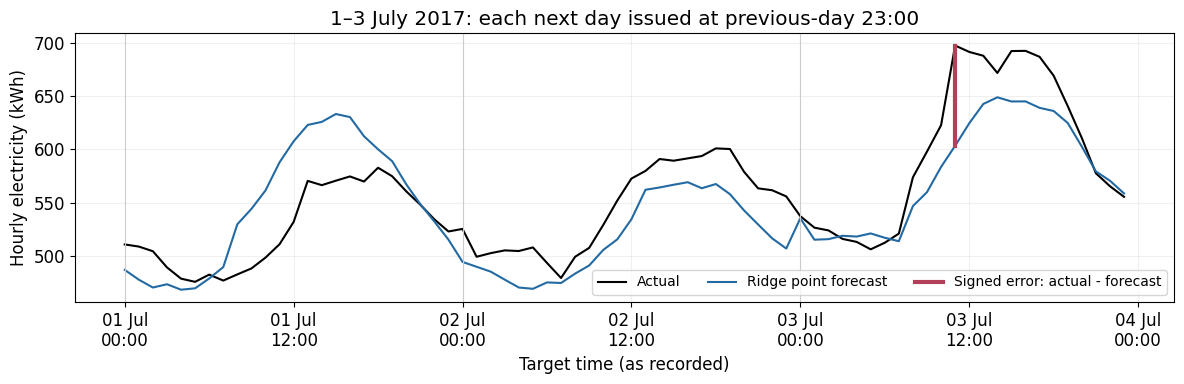

In [102]:
cal_window = calibration.loc["2017-07-01":"2017-07-03"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cal_window.index, cal_window["actual"], color="black", label="Actual")
ax.plot(cal_window.index, cal_window["corrected_forecast"], color=COLOURS["point"], label="Ridge point forecast")
marker_time = (cal_window["actual"]-cal_window["corrected_forecast"]).abs().idxmax()
ax.plot([marker_time]*2, cal_window.loc[marker_time, ["corrected_forecast", "actual"]],
        color="#b34058", linewidth=3, label="Signed error: actual - forecast")
for day in cal_window.index.normalize().unique():
    ax.axvline(day, color="#cccccc", linewidth=.8)
ax.set(ylabel="Hourly electricity (kWh)", xlabel="Target time (as recorded)",
       title="1–3 July 2017: each next day issued at previous-day 23:00")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
ax.legend(ncol=3, fontsize=10)
export_figure(fig, "U01", "w4d2_U01_building_forecast", 3, "U0", "2017-07-01 to 2017-07-03",
              "kWh per hourly interval", "Held-out calibration point forecasts and signed error", len(cal_window))

### Four representations of forecast uncertainty

The next example uses synthetic data to distinguish a point forecast, quantiles,
a prediction interval and complete scenario trajectories. The interval is bounded
by the 10th and 90th quantiles; the difference between them is its width.
These curves are illustrative, not fitted forecasts for the Robin building.

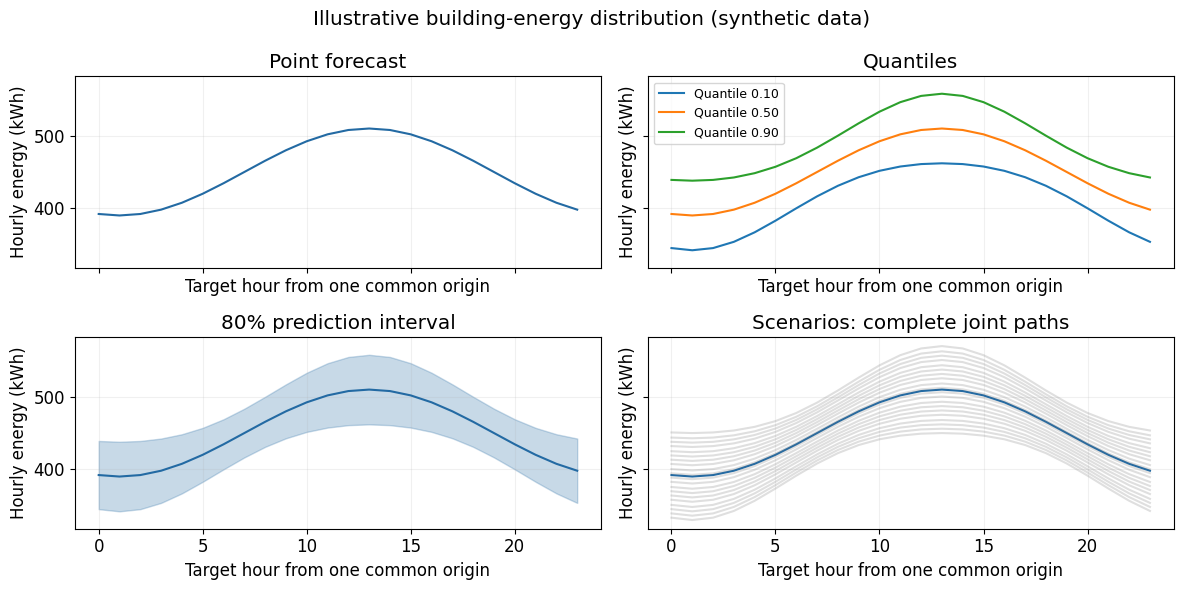

In [103]:
# Explicitly illustrative, coherent distribution; NOT measurements or a fitted uncertainty model.
illustrative_hour = np.arange(24)
illustrative_centre = 450+60*np.sin(2*np.pi*(illustrative_hour-7)/24)
illustrative_scale = .7+.3*np.sin(2*np.pi*(illustrative_hour-7)/24)**2
illustrative_paths = illustrative_centre + np.linspace(-60, 60, 101)[:, None]*illustrative_scale
illustrative_quantiles = np.quantile(illustrative_paths, [.10, .50, .90], axis=0, method="linear")
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
axes[0,0].plot(illustrative_hour, illustrative_centre, color=COLOURS["point"])
axes[0,0].set_title("Point forecast")
for tau, values in zip([.10,.50,.90], illustrative_quantiles):
    axes[0,1].plot(illustrative_hour, values, label=f"Quantile {tau:.2f}")
axes[0,1].legend(fontsize=9); axes[0,1].set_title("Quantiles")
axes[1,0].fill_between(illustrative_hour, illustrative_quantiles[0], illustrative_quantiles[2], alpha=.25, color=COLOURS["point"])
axes[1,0].plot(illustrative_hour, illustrative_quantiles[1], color=COLOURS["point"])
axes[1,0].set_title("80% prediction interval")
axes[1,1].plot(illustrative_hour, illustrative_centre, color=COLOURS["point"])
axes[1,1].plot(illustrative_hour, illustrative_paths[np.linspace(0,100,20,dtype=int)].T, alpha=.25, color=COLOURS["scenario"])
axes[1,1].set_title("Scenarios: complete joint paths")
for ax in axes.flat: ax.set(xlabel="Target hour from one common origin", ylabel="Hourly energy (kWh)")
fig.suptitle("Illustrative building-energy distribution (synthetic data)")
export_figure(fig, "U02", "w4d2_U02_forecast_representations", 6, "U0", "Constructed 24-hour example",
              "illustrative kWh", "Four representations of one constructed distribution", "101 equally weighted paths",
              status="illustrative", source_hash="not applicable")

### Training, calibration and testing

The table summarises the role of each period. Test observations are used only for evaluation.

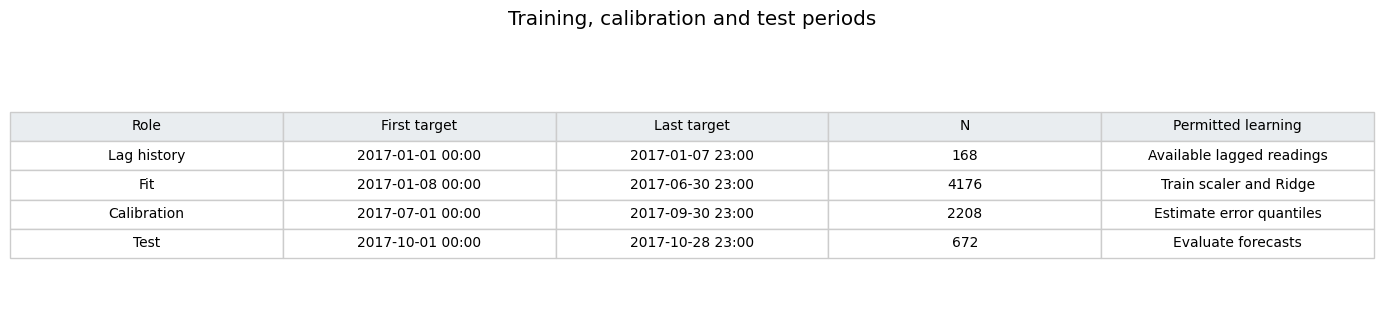

In [104]:
role_table = pd.DataFrame([
    ["Lag history", "2017-01-01 00:00", "2017-01-07 23:00", 168, "Available lagged readings"],
    ["Fit", *BUILDING_SPLITS["training"], len(X_train), "Train scaler and Ridge"],
    ["Calibration", *BUILDING_SPLITS["calibration"], len(calibration), "Estimate error quantiles"],
    ["Test", *BUILDING_SPLITS["test"], len(test), "Evaluate forecasts"]],
    columns=["Role", "First target", "Last target", "N", "Permitted learning"])
fig = table_figure(role_table, "Training, calibration and test periods", (14, 3.5), 10)
export_figure(fig, "U03", "w4d2_U03_data_roles", 9, "U0", "2017-01-01 to 2017-10-28",
              "source-clock dates; counts", "Exact roles/dates/counts; new fit versus Day 1", "168 history /4176 fit /2208 cal /672 test")

## U1 — Calibration errors

For each calibration target, calculate $e_t=y_t-\hat y_t$, where $\hat y_t$ is the
Ridge forecast after projecting any negative value to zero. The model is trained once;
this correction is post-processing, not a second fit. The preceding output reports
how many forecasts were changed.

Positive errors indicate underestimated demand; negative errors indicate
overestimated demand. We use these held-out errors to construct prediction intervals.

**Predict:** will the empirical 10th and 90th percentiles be symmetric around zero?
After plotting, describe the sign and spread of the calibration errors.

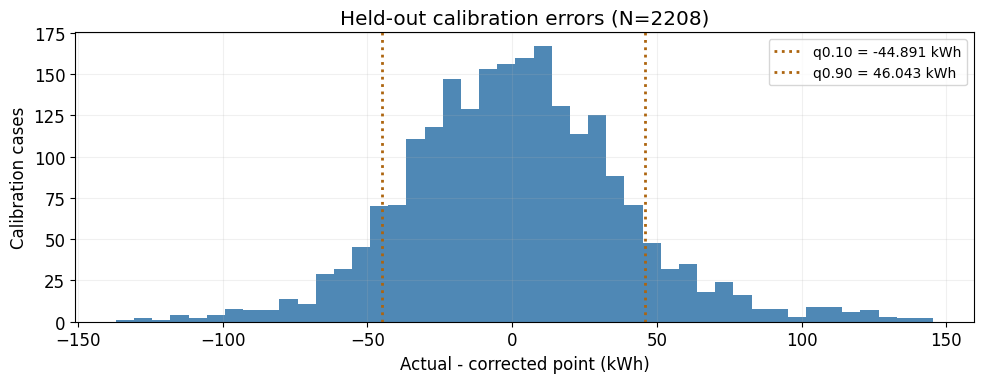

In [105]:
calibration["error"] = calibration["actual"]-calibration["corrected_forecast"]
diagnostic_quantiles = np.quantile(calibration["error"], [.10,.90], method="linear")
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(calibration["error"], bins=45, color=COLOURS["point"], alpha=.8)
for q, value in zip([.10,.90], diagnostic_quantiles):
    ax.axvline(value, color=COLOURS["Pooled"], linestyle=":" , linewidth=2,
               label=f"q{q:.2f} = {value:.3f} kWh")
ax.set(xlabel="Actual - corrected point (kWh)", ylabel="Calibration cases", title=f"Held-out calibration errors (N={len(calibration)})")
ax.legend(fontsize=10)
export_figure(fig, "U04", "w4d2_U04_calibration_residuals", 10, "U1", "2017-07-01 to 2017-09-30",
              "kWh; counts", "All calibration errors, zero and 10/90 percentiles", len(calibration))

In [106]:
print(f"U1: calibration 10th/90th errors are {diagnostic_quantiles[0]:.3f}/{diagnostic_quantiles[1]:.3f} kWh: nearly, not exactly, symmetric around zero. The histogram alone does not establish normality.")

U1: calibration 10th/90th errors are -44.891/46.043 kWh: nearly, not exactly, symmetric around zero. The histogram alone does not establish normality.


## U2 — Task A: pooled prediction intervals (9 minutes + 3 debrief)

**Pooled** means that we use calibration errors from all hours together, rather than
estimating a separate error distribution for each hour.

For a central $100(1-\alpha)\%$ prediction interval, add the calibration-error
quantiles at $\alpha/2$ and $1-\alpha/2$ to the point forecast. For 80% coverage,
these are the 0.10 and 0.90 quantiles.

Calculate `pooled_offsets`, then construct `pooled_raw` with `lower` and `upper`
columns indexed by the test timestamps. The next cell projects negative endpoints
to zero. Building electricity has no upper bound of 1; retain the raw endpoints.

**Predict:** which part of the pooled interval is constant across target hours?

In [107]:
pooled_offsets = np.quantile(calibration["error"], [ALPHA/2, 1-ALPHA/2], method="linear")
pooled_raw = pd.DataFrame(index=test.index.copy())
pooled_raw["lower"] = test["corrected_forecast"]+pooled_offsets[0]
pooled_raw["upper"] = test["corrected_forecast"]+pooled_offsets[1]

Pooled offsets (kWh): [-44.89105811  46.04289927] | negative endpoint corrections: {'lower': 0, 'upper': 0}


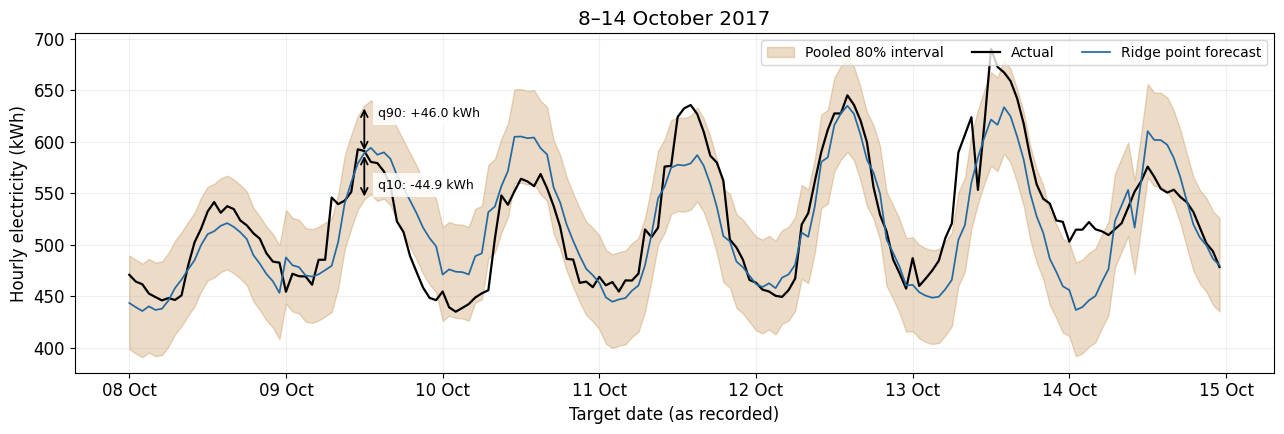

In [108]:
pooled_bounded = pooled_raw.clip(lower=0)
pooled_clip_counts = {column: int((pooled_raw[column] < 0).sum()) for column in ["lower", "upper"]}
print("Pooled offsets (kWh):", pooled_offsets, "| negative endpoint corrections:", pooled_clip_counts)
window = test.loc["2017-10-08":"2017-10-14"]
fig, ax = plt.subplots(figsize=(13, 4.5))
building_band(ax, window, pooled_bounded.loc[window.index], "Pooled")
ax.set_xlabel("Target date (as recorded)")
ax.set_title(f"8–14 October 2017")
# Show the error offsets relative to the point forecast at one target.
offset_time = pd.Timestamp("2017-10-09 12:00")
point_at_time = window.loc[offset_time, "corrected_forecast"]
for value, label, side in [(pooled_offsets[0], "q10", -1), (pooled_offsets[1], "q90", 1)]:
    ax.annotate("", xy=(offset_time, point_at_time + value),
                xytext=(offset_time, point_at_time),
                arrowprops={"arrowstyle": "<->", "color": "black", "linewidth": 1.3})
    ax.annotate(f"{label}: {value:+.1f} kWh", xy=(offset_time, point_at_time + value/2),
                xytext=(10, side*9), textcoords="offset points", fontsize=9,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": .85})
export_figure(fig, "U05", "w4d2_U05_pooled_interval", 11, "U2", "Plot 2017-10-08 to 14; scores/corrections 1–28 October",
              "kWh per hourly interval", "Pooled 80% band, quantile-offset arrows and actual clipping counts", "168 plotted /672 test /2208 calibration")

In [109]:
print(f"Task A: offsets {pooled_offsets[0]:.3f}, {pooled_offsets[1]:.3f} kWh give a constant raw width of {np.diff(pooled_offsets)[0]:.3f} kWh. Constant width does not imply constant hourly coverage.")
print(f"The nonnegative endpoint rule changes {sum(pooled_clip_counts.values())} endpoints in this test; no support violation is invented for the illustration.")

Task A: offsets -44.891, 46.043 kWh give a constant raw width of 90.934 kWh. Constant width does not imply constant hourly coverage.
The nonnegative endpoint rule changes 0 endpoints in this test; no support violation is invented for the illustration.


## U3 — Task B: condition on target hour (9 minutes + 3 debrief)

We next estimate calibration-error quantiles separately for each hour of the day.
Each group contains 92 observations. Smaller groups provide less stable estimates
of the tails of the error distribution.

For each hour, calculate the 10th and 90th percentiles. Match these offsets to the
test target hour, add them to the point forecast and project negative endpoints to zero.
The offsets can be asymmetric, so the interval need not contain its point forecast.

**Predict:** which hours might require wider intervals? Compare the calibration
distributions before examining test performance.

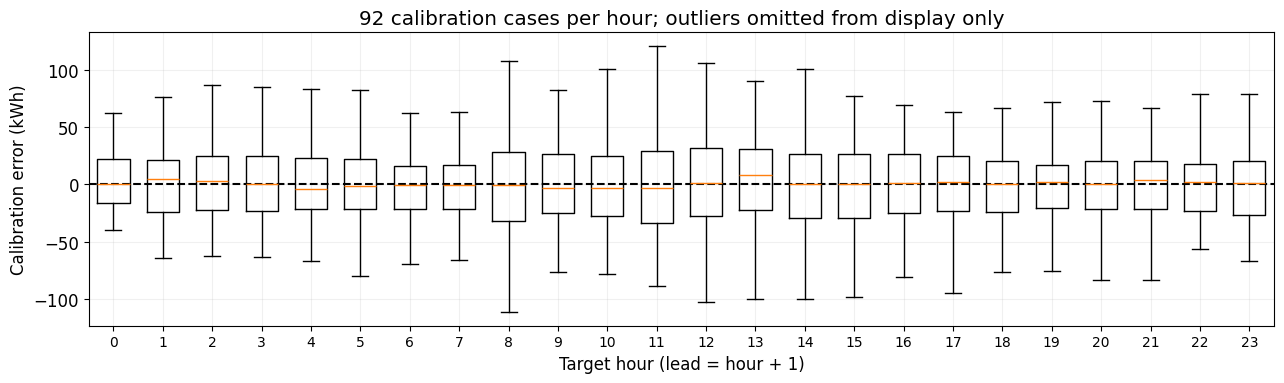

In [110]:
hour_counts = calibration.groupby("hour").size().reindex(range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(13, 4))
ax.boxplot([calibration.loc[calibration["hour"] == h, "error"].to_numpy() for h in range(24)],
           positions=np.arange(24), widths=.65, showfliers=False)
ax.axhline(0, color="black", linestyle="--")
ax.set(xticks=np.arange(24), xlabel="Target hour (lead = hour + 1)", ylabel="Calibration error (kWh)",
       title="92 calibration cases per hour; outliers omitted from display only")
ax.tick_params(axis="x", labelsize=10)
export_figure(fig, "U06", "w4d2_U06_errors_by_hour", 13, "U3", "2017-07-01 to 2017-09-30",
              "kWh; counts", "Calibration error distributions by target hour", hour_counts.to_dict())

In [111]:
hour_rows = []
for hour in range(24):
    errors = calibration.loc[calibration["hour"] == hour, "error"]
    offsets = np.quantile(errors, [.10, .90], method="linear")
    hour_rows.append({"hour": hour, "lower_offset": offsets[0], "upper_offset": offsets[1],
                      "n_calibration": len(errors)})
hourly_offsets = pd.DataFrame(hour_rows).set_index("hour")
hourly_raw = pd.DataFrame(index=test.index.copy())
hourly_raw["lower"] = test["corrected_forecast"] + test["hour"].map(hourly_offsets["lower_offset"])
hourly_raw["upper"] = test["corrected_forecast"] + test["hour"].map(hourly_offsets["upper_offset"])

Endpoint correction counts: {'Pooled': {'lower': 0, 'upper': 0}, 'Target-hour': {'lower': 0, 'upper': 0}}


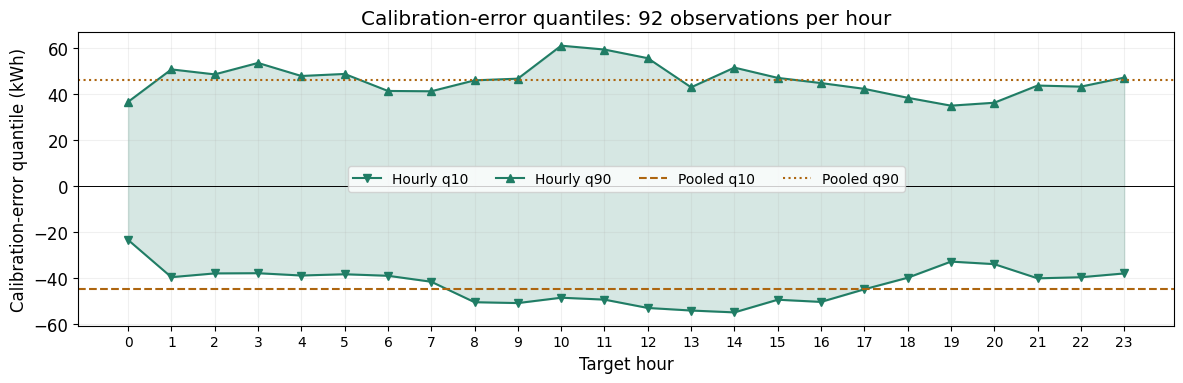

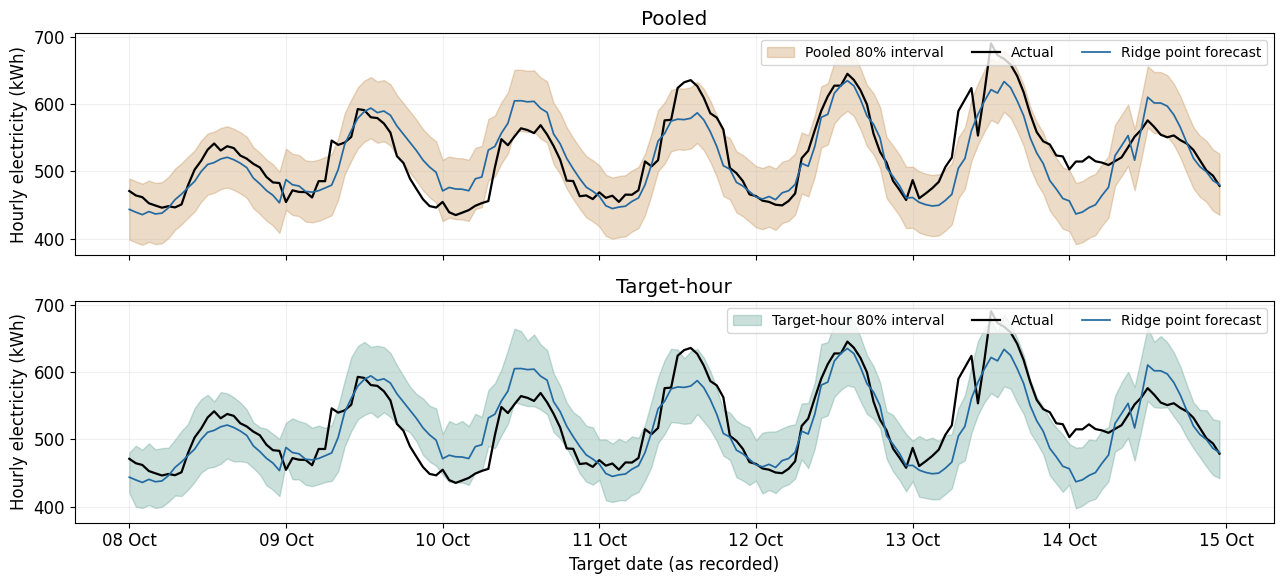

In [112]:
hourly_bounded = hourly_raw.clip(lower=0)
intervals = {"Pooled": pooled_bounded, "Target-hour": hourly_bounded}
raw_intervals = {"Pooled": pooled_raw, "Target-hour": hourly_raw}
endpoint_clips = {name: {col: int((raw[col] < 0).sum()) for col in ["lower","upper"]}
                  for name, raw in raw_intervals.items()}
print("Endpoint correction counts:", endpoint_clips)
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(hourly_offsets.index, hourly_offsets["lower_offset"], hourly_offsets["upper_offset"], color=COLOURS["Target-hour"], alpha=.18)
ax.plot(hourly_offsets.index, hourly_offsets["lower_offset"], "v-", color=COLOURS["Target-hour"], label="Hourly q10")
ax.plot(hourly_offsets.index, hourly_offsets["upper_offset"], "^-", color=COLOURS["Target-hour"], label="Hourly q90")
ax.axhline(pooled_offsets[0], color=COLOURS["Pooled"], linestyle="--", label="Pooled q10")
ax.axhline(pooled_offsets[1], color=COLOURS["Pooled"], linestyle=":", label="Pooled q90")
ax.axhline(0, color="black", linewidth=.7)
ax.set(xticks=np.arange(24), xlabel="Target hour", ylabel="Calibration-error quantile (kWh)",
       title="Calibration-error quantiles: 92 observations per hour")
ax.legend(fontsize=10, ncol=4); ax.tick_params(axis="x", labelsize=10)
export_figure(fig, "U07", "w4d2_U07_hourly_offsets", 14, "U3", "July–September 2017 calibration",
              "kWh; counts", "Hourly offsets, pooled reference offsets, group sample counts", hour_counts.to_dict())

fig, axes = plt.subplots(2,1,figsize=(13,6),sharex=True,sharey=True)
for ax, name in zip(axes, intervals):
    building_band(ax, window, intervals[name].loc[window.index], name)
    ax.set_title(name)
axes[-1].set_xlabel("Target date (as recorded)")
export_figure(fig, "U08", "w4d2_U08_interval_comparison", 15, "U3", "2017-10-08 to 2017-10-14",
              "kWh per hourly interval", "Pooled/target-hour corrected 80% bands; shared scales", len(window))

record_parts = []
for name, bounds in intervals.items():
    part = test[["origin_time", "actual", "corrected_forecast", "hour", "lead_hour"]].copy()
    part = part.rename(columns={"corrected_forecast": "point", "hour": "group"})
    part["method"], part["nominal_level"] = name, .80
    part["raw_lower"], part["raw_upper"] = raw_intervals[name]["lower"], raw_intervals[name]["upper"]
    part["lower"], part["upper"] = bounds["lower"], bounds["upper"]
    part["n_calibration_group"] = len(calibration) if name == "Pooled" else part["group"].map(hourly_offsets["n_calibration"])
    record_parts.append(part.reset_index())
interval_records = pd.concat(record_parts, ignore_index=True)

In [113]:
calibration_widths = hourly_offsets["upper_offset"]-hourly_offsets["lower_offset"]
print(f"Task B: hourly raw widths range from {calibration_widths.min():.3f} to {calibration_widths.max():.3f} kWh, versus pooled {np.diff(pooled_offsets)[0]:.3f} kWh. The plot shows narrower night/evening bands and broader daytime bands in this calibration sample; that does not guarantee better test performance.")

Task B: hourly raw widths range from 60.116 to 109.744 kWh, versus pooled 90.934 kWh. The plot shows narrower night/evening bands and broader daytime bands in this calibration sample; that does not guarantee better test performance.


**Interpret:** identify one visible difference between pooled and target-hour intervals.
Use calibration spread as an explanation, not a guarantee that conditioning improves test performance.

## U4 — Task C: hand scores and metric functions (7 minutes + 3 debrief)

For the constructed interval $[L,U]=[400,500]$ kWh and actual readings 380, 450 and
530 kWh, fill the blank columns below. These are illustrative cases, not source observations.
Use $\alpha=0.20$.

Coverage is $100\,\mathrm{mean}(L_t\leq y_t\leq U_t)$; mean width is $\mathrm{mean}(U_t-L_t)$.
The Winkler score for one observation is
$W_t=(U_t-L_t)+(2/\alpha)(L_t-y_t)\mathbf{1}(y_t<L_t)+(2/\alpha)(y_t-U_t)\mathbf{1}(y_t>U_t)$.
Average the scores over observations. At 80% the miss multiplier is 10. Endpoint equality incurs
no penalty. Width and Winkler are expressed in the target's kWh units.

Complete the metric functions using the supplied input checks. Do not silently delete
invalid or misaligned pairs. Compare methods only on identical targets and nominal levels.

,Actual (kWh),Lower,Upper,Covered?,Width (kWh),Winkler (kWh)
0,380,400,500,,,
1,450,400,500,,,
2,530,400,500,,,


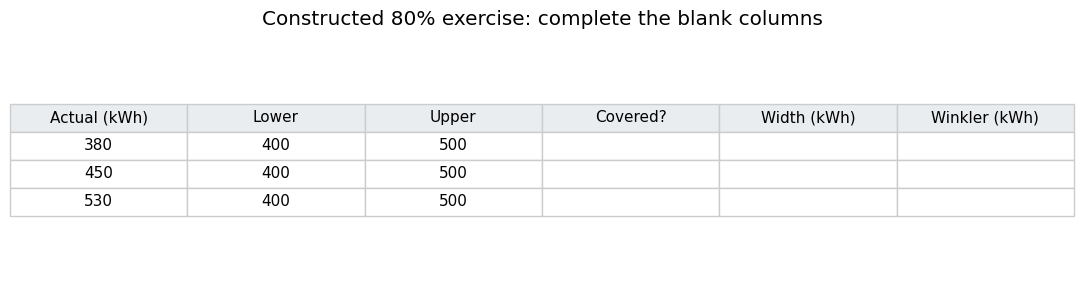

In [114]:
hand_examples = pd.DataFrame({"Actual (kWh)": [380,450,530], "Lower": [400]*3, "Upper": [500]*3,
                              "Covered?": [""]*3, "Width (kWh)": [""]*3, "Winkler (kWh)": [""]*3})
display(hand_examples)
fig = table_figure(hand_examples, "Constructed 80% exercise: complete the blank columns", (11,3))
export_figure(fig, "U11", "w4d2_U11_score_examples", 20, "U4", "Constructed three-case example",
              "kWh; coverage indicator", "Blank hand-scoring exercise", 3, status="constructed", variant="exercise", source_hash="not applicable")

def checked_arrays(*values):
    indexed = [value for value in values if isinstance(value, pd.Series)]
    if indexed:
        if len(indexed) != len(values):
            raise ValueError("Use all indexed Series or all one-dimensional arrays.")
        index = indexed[0].index
        if not index.is_unique or any(not value.index.equals(index) for value in indexed):
            raise ValueError("Actual and forecast timestamps must be unique and identical.")
    arrays = [np.asarray(value, dtype=float) for value in values]
    if any(value.ndim != 1 or len(value) == 0 for value in arrays):
        raise ValueError("Expected non-empty one-dimensional inputs.")
    if any(len(value) != len(arrays[0]) for value in arrays):
        raise ValueError("Input lengths differ.")
    if any(not np.isfinite(value).all() for value in arrays):
        raise ValueError("Non-finite input: investigate upstream instead of dropping pairs.")
    return arrays

def checked_bounds(actual, lower, upper):
    a, l, u = checked_arrays(actual, lower, upper)
    if np.any(l > u): raise ValueError("Lower bounds exceed upper bounds.")
    return a, l, u

In [115]:
def coverage(actual, lower, upper):
    '''Inclusive coverage, returned as a percentage.'''
    a, l, u = checked_bounds(actual, lower, upper)
    return 100*np.mean((l <= a) & (a <= u))

def mean_width(actual, lower, upper):
    '''Mean width on the aligned target set.'''
    a, l, u = checked_bounds(actual, lower, upper)
    return np.mean(u-l)

def winkler(actual, lower, upper, alpha=.20):
    '''Mean Winkler score; alpha is the miscoverage probability.'''
    a, l, u = checked_bounds(actual, lower, upper)
    if not np.isfinite(alpha) or not 0 < alpha < 1:
        raise ValueError("alpha must be strictly between 0 and 1.")
    return np.mean((u-l)+(2/alpha)*(l-a)*(a<l)+(2/alpha)*(a-u)*(a>u))

,Actual (kWh),Lower,Upper,Covered?,Width (kWh),Winkler (kWh)
0,380,400,500,False,100,300
1,450,400,500,True,100,100
2,530,400,500,False,100,400


Mean coverage (%), width (kWh), Winkler (kWh): 33.33333333333333 100.0 266.6666666666667


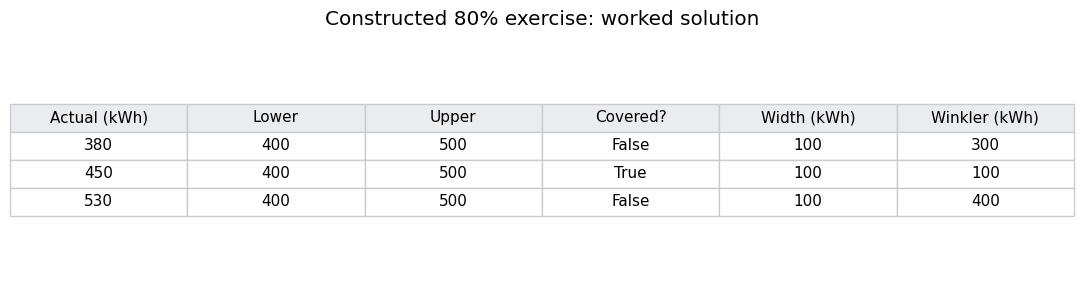

In [116]:
hand_solution = hand_examples.copy()
a = hand_solution["Actual (kWh)"].to_numpy()
l, u = hand_solution["Lower"].to_numpy(), hand_solution["Upper"].to_numpy()
hand_solution["Covered?"] = (l<=a)&(a<=u)
hand_solution["Width (kWh)"] = u-l
hand_solution["Winkler (kWh)"] = (u-l)+10*(l-a)*(a<l)+10*(a-u)*(a>u)
display(hand_solution)
print("Mean coverage (%), width (kWh), Winkler (kWh):", coverage(a,l,u), mean_width(a,l,u), winkler(a,l,u))
fig = table_figure(hand_solution, "Constructed 80% exercise: worked solution", (11,3))
export_figure(fig, "U11", "w4d2_U11_score_examples_solution", 20, "U4", "Constructed three-case example",
              "kWh; coverage indicator", "Filled instructor hand scores", 3, status="constructed", variant="solution", source_hash="not applicable")

**Break after Task C (slide 20): 15–20 minutes, outside the 200 teaching minutes.**

After the break, compare full-period and grouped results. Hourly coverage has only
28 test cases per hour and errors may be dependent. Good overall coverage does not establish
good conditional coverage. July–September calibration may transfer imperfectly to October.

,Method,Subset,N,Coverage (%),Width (kWh),Winkler (kWh)
0,Pooled,All,672,75.595,90.934,132.784
1,Pooled,Weekdays,480,72.500,90.934,141.182
2,Pooled,Weekends,192,83.333,90.934,111.788
3,Target-hour,All,672,74.256,89.153,130.720
4,Target-hour,Weekdays,480,69.375,89.153,141.540
5,Target-hour,Weekends,192,86.458,89.153,103.669


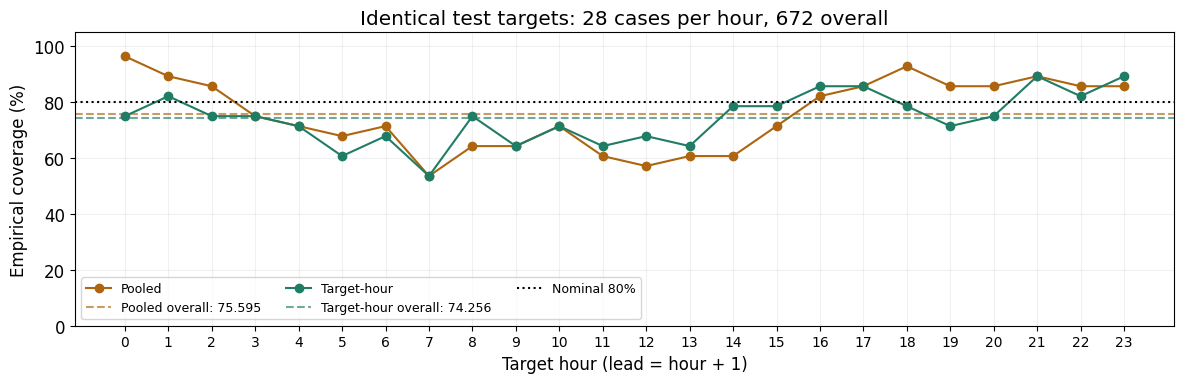

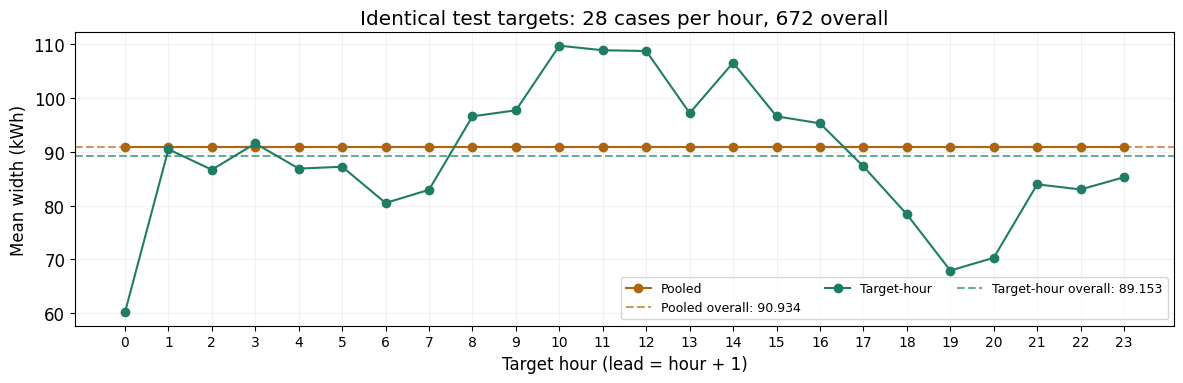

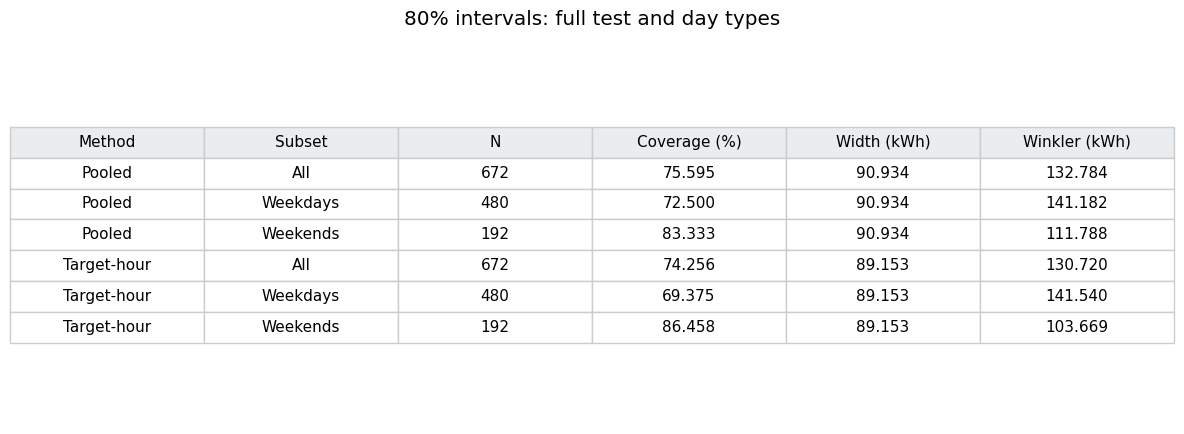

In [117]:
subsets = {"All": pd.Series(True, index=test.index), "Weekdays": ~test["is_weekend"], "Weekends": test["is_weekend"]}
score_rows, hourly_rows = [], []
for name, bounds in intervals.items():
    for subset, mask in subsets.items():
        a = test.loc[mask,"actual"]
        l, u = bounds.loc[mask,"lower"], bounds.loc[mask,"upper"]
        score_rows.append({"Method":name, "Subset":subset, "N":len(a),
            "Coverage (%)":coverage(a,l,u) if len(a) else np.nan,
            "Width (kWh)":mean_width(a,l,u) if len(a) else np.nan,
            "Winkler (kWh)":winkler(a,l,u,ALPHA) if len(a) else np.nan})
    for hour in range(24):
        mask = test["hour"] == hour
        a = test.loc[mask,"actual"]
        l, u = bounds.loc[mask,"lower"], bounds.loc[mask,"upper"]
        hourly_rows.append({"method":name,"hour":hour,"n":len(a),
            "coverage":coverage(a,l,u),"width":mean_width(a,l,u),"winkler":winkler(a,l,u,ALPHA)})
score_table, hourly_scores = pd.DataFrame(score_rows), pd.DataFrame(hourly_rows)
display(score_table.round(3))
for metric, fid, stem, slide, ylabel in [
    ("coverage","U09","w4d2_U09_coverage_by_hour",17,"Empirical coverage (%)"),
    ("width","U10","w4d2_U10_width_by_hour",18,"Mean width (kWh)")]:
    fig, ax = plt.subplots(figsize=(12,4))
    for name in intervals:
        rows = hourly_scores.loc[hourly_scores["method"] == name]
        overall_col = "Coverage (%)" if metric == "coverage" else "Width (kWh)"
        overall = score_table.loc[(score_table["Method"] == name)&(score_table["Subset"] == "All"),overall_col].iloc[0]
        ax.plot(rows["hour"], rows[metric], "o-", color=COLOURS[name], label=name)
        ax.axhline(overall, color=COLOURS[name], linestyle="--", alpha=.65, label=f"{name} overall: {overall:.3f}")
    if metric == "coverage": ax.axhline(80,color="black",linestyle=":",label="Nominal 80%")
    ax.set(xticks=np.arange(24),xlabel="Target hour (lead = hour + 1)",ylabel=ylabel,
           title="Identical test targets: 28 cases per hour, 672 overall")
    if metric == "coverage": ax.set_ylim(0,105)
    ax.tick_params(axis="x",labelsize=10); ax.legend(fontsize=9,ncol=3)
    export_figure(fig,fid,stem,slide,"U4","2017-10-01 to 2017-10-28",ylabel,
                  "Both methods' hourly and overall scores on the same targets","28/hour; 672 full test")
fig = table_figure(score_table.replace({np.nan:"undefined"}), "80% intervals: full test and day types", (12,4.5))
export_figure(fig,"U12","w4d2_U12_interval_scores",21,"U4","2017-10-01 to 2017-10-28",
              "%; kWh; counts","Two methods, full/weekday/weekend coverage width Winkler", {k:int(v.sum()) for k,v in subsets.items()})

In [118]:
full_scores = score_table.loc[score_table["Subset"] == "All"].set_index("Method")
print("Task C: covered flags are False/True/False; widths 100/100/100; Winkler 300/100/400 kWh. Mean Winkler is 800/3 kWh.")
best_winkler = full_scores["Winkler (kWh)"].idxmin()
print(f"On all 672 test targets, {best_winkler} has the lower Winkler score ({full_scores.loc[best_winkler,'Winkler (kWh)']:.3f} kWh). Compare width and coverage too; no ranking was prescribed.")
print("Hourly estimates use 28 cases only. The summer-to-October transfer and serial dependence limit what one nominal-looking total can establish.")

Task C: covered flags are False/True/False; widths 100/100/100; Winkler 300/100/400 kWh. Mean Winkler is 800/3 kWh.
On all 672 test targets, Target-hour has the lower Winkler score (130.720 kWh). Compare width and coverage too; no ranking was prescribed.
Hourly estimates use 28 cases only. The summer-to-October transfer and serial dependence limit what one nominal-looking total can establish.


## U5 — Task D: nominal coverage sensitivity (8 minutes + 4 debrief)

We compare prediction intervals with nominal coverage of 50%, 80% and 95%.
The supplied code changes only the calibration-error quantiles. The point model,
hourly groups, calibration period and test targets remain unchanged.

**Predict:** how should interval width change as nominal coverage increases?

Run the calculations and compare nominal coverage, empirical coverage and mean width.
Explain the trade-off in two sentences. Do not select a coverage level using this test
set or compare Winkler scores across levels without accounting for the change in $\alpha$.

,nominal,n,coverage,width
0,0.50,672,47.024,47.959
1,0.80,672,74.256,89.153
2,0.95,672,94.643,147.899


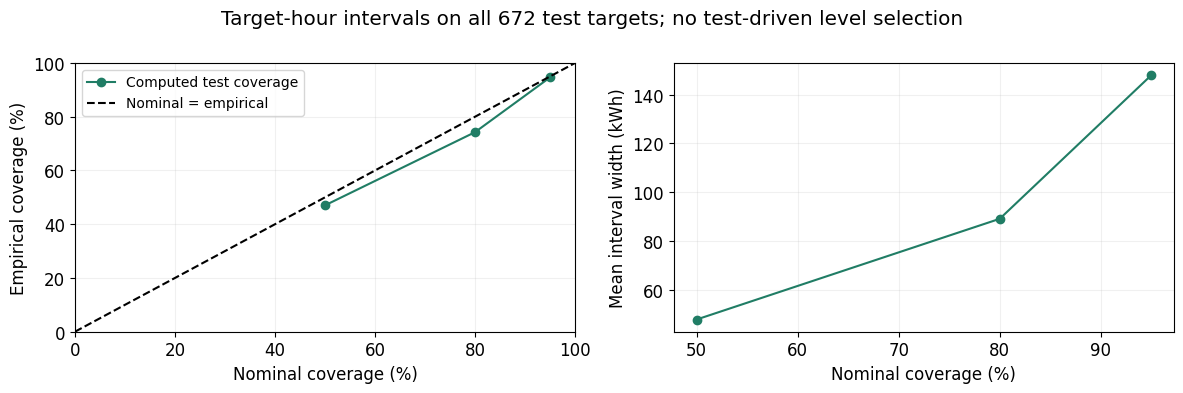

In [119]:
level_intervals = {}
for nominal in [.50,.80,.95]:
    alpha = 1-nominal
    probabilities = [alpha/2,1-alpha/2]
    lower_lookup, upper_lookup = {}, {}
    for hour in range(24):
        errors = calibration.loc[calibration["hour"] == hour,"error"]
        offsets = np.quantile(errors, probabilities, method="linear")
        lower_lookup[hour], upper_lookup[hour] = offsets
    bounds = pd.DataFrame(index=test.index.copy())
    bounds["lower"] = test["corrected_forecast"]+test["hour"].map(lower_lookup)
    bounds["upper"] = test["corrected_forecast"]+test["hour"].map(upper_lookup)
    level_intervals[nominal] = bounds.clip(lower=0)
level_rows = []
for nominal, bounds in level_intervals.items():
    a, l, u = test["actual"], bounds["lower"], bounds["upper"]
    level_rows.append({"nominal": nominal, "n": len(a),
                      "coverage": coverage(a, l, u), "width": mean_width(a, l, u)})
level_scores = pd.DataFrame(level_rows)
display(level_scores.round(3))
fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(100*level_scores["nominal"],level_scores["coverage"],"o-",color=COLOURS["Target-hour"],label="Computed test coverage")
axes[0].plot([0,100],[0,100],"k--",label="Nominal = empirical")
axes[0].set(xlim=(0,100),ylim=(0,100),xlabel="Nominal coverage (%)",ylabel="Empirical coverage (%)")
axes[0].legend(fontsize=10)
axes[1].plot(100*level_scores["nominal"],level_scores["width"],"o-",color=COLOURS["Target-hour"])
axes[1].set(xlabel="Nominal coverage (%)",ylabel="Mean interval width (kWh)")
fig.suptitle("Target-hour intervals on all 672 test targets; no test-driven level selection")
export_figure(fig,"U13","w4d2_U13_nominal_level_sensitivity",22,"U5","2017-10-01 to 2017-10-28",
              "%; kWh","Computed nominal/empirical coverage and width; same groups/targets",672)

In [120]:
print("Task D: above the diagonal is empirical overcoverage; below is undercoverage. The table shows how much width changes alongside coverage:")
for row in level_scores.itertuples():
    print(f"Nominal {100*row.nominal:.0f}%: coverage {row.coverage:.3f}%, mean width {row.width:.3f} kWh.")
print("An operator also needs repeated-origin evaluation, subgroup/count diagnostics and evidence that calibration transfers to new conditions. These empirical intervals carry no finite-sample guarantee.")

Task D: above the diagonal is empirical overcoverage; below is undercoverage. The table shows how much width changes alongside coverage:
Nominal 50%: coverage 47.024%, mean width 47.959 kWh.
Nominal 80%: coverage 74.256%, mean width 89.153 kWh.
Nominal 95%: coverage 94.643%, mean width 147.899 kWh.
An operator also needs repeated-origin evaluation, subgroup/count diagnostics and evidence that calibration transfers to new conditions. These empirical intervals carry no finite-sample guarantee.


## U6 — Quantile regression

Error-based prediction intervals add calibration offsets to a fixed point model. Quantile regression
instead estimates conditional thresholds directly by minimising pinball loss. The core tutorial illustrates
the loss. The self-study extension fits two linear quantile-regression models.

Our unscaled convention is $\rho_\tau(e)=\max\{\tau e,(\tau-1)e\}$ with $e=y-q$ and
$0<\tau<1$. The mean loss at $\tau=0.5$ equals half MAE. FPP's quantile-score convention
has an additional factor two. A point forecast is not automatically a median.

**Question:** which sign of error does a high quantile penalise more? Relate it to underprediction.

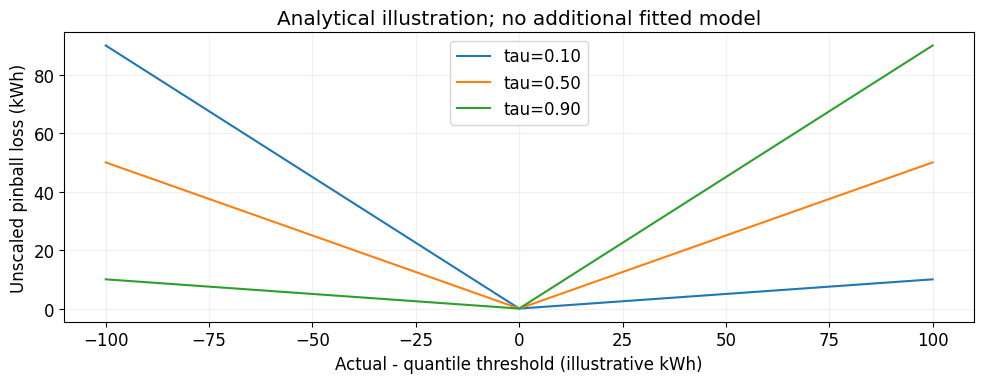

In [121]:
def pinball(actual, quantile_forecast, tau):
    a,q = checked_arrays(actual,quantile_forecast)
    if not np.isfinite(tau) or not 0<tau<1: raise ValueError("tau must be strictly between 0 and 1.")
    error = a-q
    return np.mean(np.maximum(tau*error,(tau-1)*error))

illustrative_errors = np.linspace(-100,100,201)
fig,ax = plt.subplots(figsize=(10,4))
for tau in [.10,.50,.90]:
    ax.plot(illustrative_errors,np.maximum(tau*illustrative_errors,(tau-1)*illustrative_errors),label=f"tau={tau:.2f}")
ax.set(xlabel="Actual - quantile threshold (illustrative kWh)",ylabel="Unscaled pinball loss (kWh)")
ax.legend(); ax.set_title("Analytical illustration; no additional fitted model")
export_figure(fig,"U14","w4d2_U14_pinball_loss",23,"U6","Analytical signed-error curve",
              "illustrative kWh","Unscaled pinball; no factor two",201,status="analytical",source_hash="not applicable")

## U7 — Complete daily error vectors and dependence

The supplied forecasts share one previous-day 23:00 origin for every complete day.
We build a **92 × 24** calibration-error matrix by explicit date/hour indexing,
rather than reshaping without checking the dates and hours. Each row contains held-out errors for one complete daily forecast.

For the pre-specified **8 October 2017** target day, add each of the 92 historical daily
error vectors once to its 24 nonnegative point forecasts, then project negative values
to zero. All scenarios have weight $1/92$. Preserve the raw matrices and clipping counts.

This is an **illustrative empirical scenario forecast**, not a proven calibrated operational
model. Using July–September vectors for an October Sunday assumes stability across seasons
and day types. One target day cannot establish joint out-of-sample accuracy.

Calibration matrix: (92, 24) | target origin: 2017-10-07 23:00:00
Actual negative scenario corrections: 0


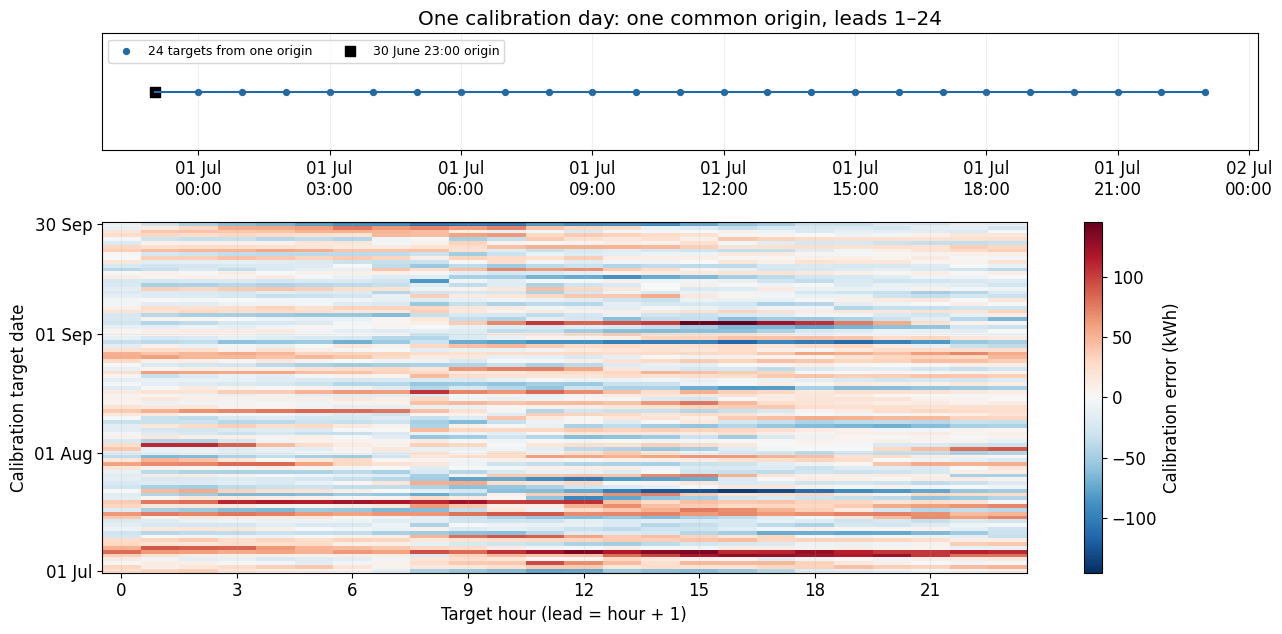

In [122]:
daily_errors = calibration[["target_date","hour","origin_time","error"]].copy()
residual_matrix = daily_errors.pivot(index="target_date",columns="hour",values="error").sort_index()
residual_matrix = residual_matrix.reindex(columns=range(24))
target_day = test.loc["2017-10-08"].copy()
target_profile = target_day["corrected_forecast"].to_numpy()
ensemble_A_raw = target_profile[None,:]+residual_matrix.to_numpy()
ensemble_A = np.maximum(0,ensemble_A_raw)
scenario_clip_count = int((ensemble_A_raw<0).sum())
S,H = ensemble_A.shape
scenario_weights = np.full(S,1/S)
print("Calibration matrix:",residual_matrix.shape,"| target origin:",target_day["origin_time"].iloc[0])
print("Actual negative scenario corrections:",scenario_clip_count)

fig,axes = plt.subplots(2,1,figsize=(13,6.5),gridspec_kw={"height_ratios":[1,3]})
example_day = calibration.loc["2017-07-01"]
origin = example_day["origin_time"].iloc[0]
axes[0].plot([origin,example_day.index[-1]],[0,0],color=COLOURS["point"])
axes[0].scatter(example_day.index,np.zeros(24),color=COLOURS["point"],s=18,label="24 targets from one origin")
axes[0].scatter([origin],[0],marker="s",s=60,color="black",label="30 June 23:00 origin")
axes[0].set(yticks=[],ylim=(-.5,.5),title="One calibration day: one common origin, leads 1–24")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
axes[0].legend(fontsize=9,ncol=2,loc="upper left")
limit = float(np.max(np.abs(residual_matrix.to_numpy())))
date_edges = np.r_[mdates.date2num(residual_matrix.index),mdates.date2num(residual_matrix.index[-1]+pd.Timedelta(days=1))]
mesh = axes[1].pcolormesh(np.arange(25)-.5,date_edges,residual_matrix.to_numpy(),cmap="RdBu_r",vmin=-limit,vmax=limit,shading="flat")
axes[1].yaxis_date()
# Label row centres, not the 1 October upper boundary, which is outside calibration.
calibration_label_days = pd.to_datetime(["2017-07-01","2017-08-01","2017-09-01","2017-09-30"])
axes[1].set_yticks(mdates.date2num(calibration_label_days+pd.Timedelta(hours=12)))
axes[1].yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[1].set(xlabel="Target hour (lead = hour + 1)",ylabel="Calibration target date",xticks=np.arange(0,24,3))
colourbar = fig.colorbar(mesh,ax=axes[1],label="Calibration error (kWh)")
colourbar.solids.set_rasterized(False)  # Keep the colour scale vector in the PDF too.
export_figure(fig,"U15","w4d2_U15_daily_error_matrix",25,"U7","2017-07-01 to 2017-09-30",
              "kWh; source-clock dates","Actual daily residual matrix and common-origin schematic","92 days ×24 hours")

### Remove cross-hour dependence

Ensemble A retains complete daily error vectors. For ensemble B, shuffle the values
independently within each hourly column. This preserves the sample for each hour but
changes how values are combined across a day. The next figure shows 20 trajectories
from each ensemble and the cross-hour correlations calculated from all 92 trajectories.

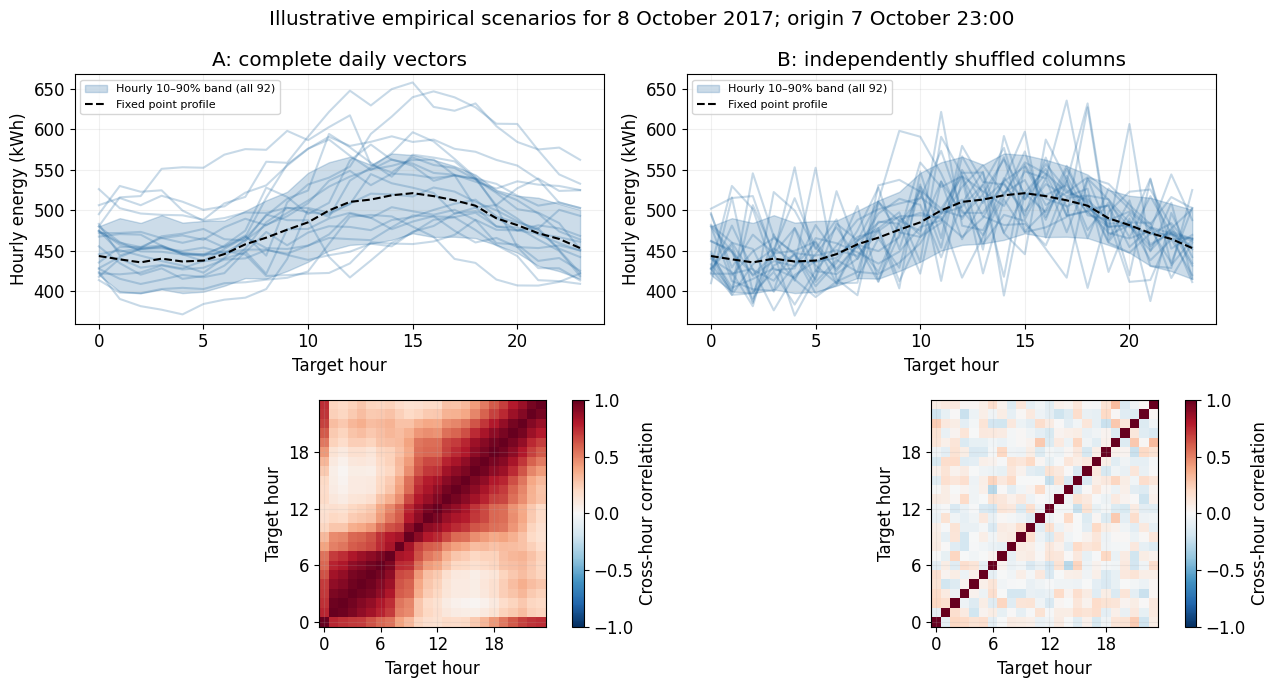

In [123]:
# Supplied controlled comparison. Shuffle columns, not complete rows.
rng = np.random.default_rng(SEED)
ensemble_B = ensemble_A.copy()
for hour in range(H): ensemble_B[:,hour] = ensemble_A[rng.permutation(S),hour]
# B permutes already-corrected values; no second support correction is applied.
bands_A = np.quantile(ensemble_A,[.10,.90],axis=0,method="linear")
bands_B = np.quantile(ensemble_B,[.10,.90],axis=0,method="linear")
correlation_A = np.corrcoef(ensemble_A,rowvar=False)
correlation_B = np.corrcoef(ensemble_B,rowvar=False)
fig,axes = plt.subplots(2,2,figsize=(13,7),gridspec_kw={"height_ratios":[1.1,1]})
for ax,values,bands,name in zip(axes[0],[ensemble_A,ensemble_B],[bands_A,bands_B],["A: complete daily vectors","B: independently shuffled columns"]):
    ax.fill_between(np.arange(24),bands[0],bands[1],color=COLOURS["point"],alpha=.23,label="Hourly 10–90% band (all 92)")
    ax.plot(np.arange(24),values[:20].T,color=COLOURS["point"],alpha=.25)
    ax.plot(np.arange(24),target_profile,"k--",label="Fixed point profile")
    ax.set(title=name,xlabel="Target hour",ylabel="Hourly energy (kWh)")
    ax.legend(fontsize=8)
common_limits = (min(ensemble_A[:20].min(),ensemble_B[:20].min(),bands_A.min(),target_profile.min())-10,
                 max(ensemble_A[:20].max(),ensemble_B[:20].max(),bands_A.max(),target_profile.max())+10)
for ax in axes[0]: ax.set_ylim(common_limits)
for ax,corr in zip(axes[1],[correlation_A,correlation_B]):
    mesh = ax.pcolormesh(np.arange(25)-.5,np.arange(25)-.5,np.ma.masked_invalid(corr),cmap="RdBu_r",vmin=-1,vmax=1,shading="flat")
    ax.set(xlabel="Target hour",ylabel="Target hour",xticks=np.arange(0,24,6),yticks=np.arange(0,24,6),aspect="equal")
    colourbar = fig.colorbar(mesh,ax=ax,label="Cross-hour correlation",fraction=.06)
    colourbar.solids.set_rasterized(False)
fig.suptitle("Illustrative empirical scenarios for 8 October 2017; origin 7 October 23:00")
export_figure(fig,"U16","w4d2_U16_dependence_experiment",26,"U7","Target 2017-10-08; calibration July–September",
              "kWh; correlation","20 fixed paths and full-sample correlation; controlled marginal-preserving shuffle", "S=92 each, shown indices0–19",status="illustrative empirical")

### Task E: check marginals and daily energy (9 minutes + 3 debrief)

The scenario construction is supplied. Check that sorted hourly columns match between A and B,
then check their hourly means and 10th/90th quantiles. Complete the equality checks below.
Do not require shuffled finite-sample correlations to equal zero exactly.

Then sum each scenario's 24 hourly **energy** readings to obtain daily kWh and calculate
its ensemble's 10th/90th daily-total percentiles. **Do not multiply by duration again.**

**Predict:** will equal hourly samples imply equal daily means, spreads and tails?
After plotting, explain what changed and state one transfer limitation. Summed hourly
endpoints are not generally an 80% daily interval.

In [124]:
np.testing.assert_array_equal(np.sort(ensemble_A,axis=0),np.sort(ensemble_B,axis=0))
np.testing.assert_allclose(ensemble_A.mean(axis=0),ensemble_B.mean(axis=0),rtol=0,atol=1e-10)
np.testing.assert_array_equal(bands_A,bands_B)

In [125]:
daily_energy_A = ensemble_A.sum(axis=1)
daily_energy_B = ensemble_B.sum(axis=1)
daily_quantiles_A = np.quantile(daily_energy_A,[.10,.90],method="linear")
daily_quantiles_B = np.quantile(daily_energy_B,[.10,.90],method="linear")

,ensemble,n,weight,mean,std,q0.10,q0.90
0,A,92,0.011,11455.819,653.927,10756.811,12121.489
1,B,92,0.011,11455.819,203.371,11179.216,11717.325


Full-ensemble correlation diagnostics: {'A_mean_off_diagonal_correlation': 0.4861674018389752, 'B_mean_off_diagonal_correlation': 0.008804709581578031}
Scenario hourly band vs target-hour interval maximum difference (kWh): 1.1368683772161603e-13


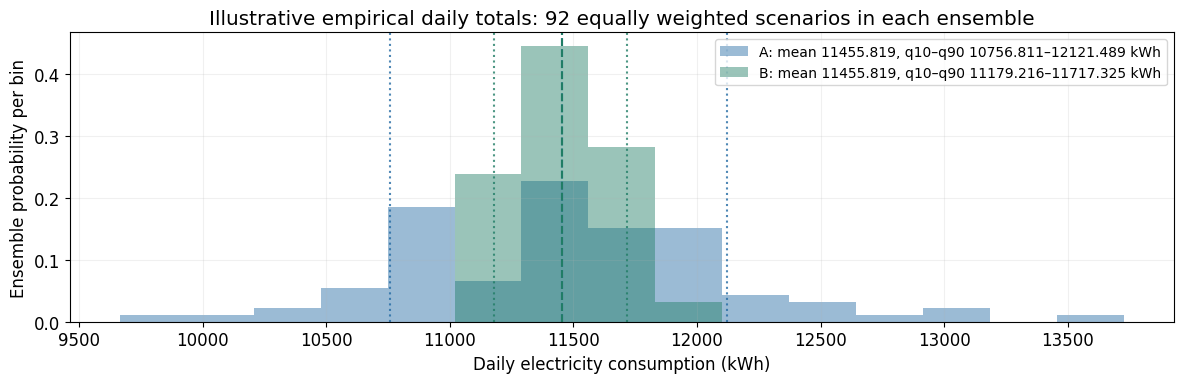

In [126]:
energy_summary = pd.DataFrame([
    {"ensemble":name,"n":len(values),"weight":1/len(values),"mean":values.mean(),
     "std":values.std(ddof=1),"q0.10":qs[0],"q0.90":qs[1]}
    for name,values,qs in [("A",daily_energy_A,daily_quantiles_A),("B",daily_energy_B,daily_quantiles_B)]])
display(energy_summary.round(3))
upper_triangle = np.triu_indices(24,1)
dependence_summary = {"A_mean_off_diagonal_correlation":float(np.nanmean(correlation_A[upper_triangle])),
                      "B_mean_off_diagonal_correlation":float(np.nanmean(correlation_B[upper_triangle]))}
print("Full-ensemble correlation diagnostics:",dependence_summary)
scenario_band_difference = float(np.max(np.abs(bands_A-hourly_bounded.loc[target_day.index].to_numpy().T)))
print("Scenario hourly band vs target-hour interval maximum difference (kWh):",scenario_band_difference)
common_bins = np.linspace(min(daily_energy_A.min(),daily_energy_B.min()),max(daily_energy_A.max(),daily_energy_B.max()),16)
fig,ax = plt.subplots(figsize=(12,4))
for name,values,qs,colour in [("A",daily_energy_A,daily_quantiles_A,COLOURS["point"]),("B",daily_energy_B,daily_quantiles_B,COLOURS["Target-hour"])]:
    ax.hist(values,bins=common_bins,weights=scenario_weights,alpha=.45,color=colour,
            label=f"{name}: mean {values.mean():.3f}, q10–q90 {qs[0]:.3f}–{qs[1]:.3f} kWh")
    ax.axvline(values.mean(),color=colour,linestyle="--")
    for value in qs: ax.axvline(value,color=colour,linestyle=":",alpha=.8)
ax.set(xlabel="Daily electricity consumption (kWh)",ylabel="Ensemble probability per bin",
       title="Illustrative empirical daily totals: 92 equally weighted scenarios in each ensemble")
ax.legend(fontsize=10)
export_figure(fig,"U17","w4d2_U17_daily_energy",27,"U7","Target 2017-10-08; common origin 7 October 23:00",
              "daily kWh; probability","Actual computed daily total distributions; common bins/equal weights", "92 each; weights1/92",status="illustrative empirical")

In [127]:
print("Task E: every hourly sample and empirical band is unchanged, but the assignment of outcomes to complete paths changes.")
print(f"Daily means agree ({daily_energy_A.mean():.3f} kWh); standard deviations are {daily_energy_A.std(ddof=1):.3f} (A) and {daily_energy_B.std(ddof=1):.3f} (B) kWh. Interpret the actual direction rather than assuming it.")
print(f"Mean off-diagonal correlations: {dependence_summary['A_mean_off_diagonal_correlation']:.3f} (A), {dependence_summary['B_mean_off_diagonal_correlation']:.3f} (B), not exact independence.")
print("Summer error vectors transferred to one October Sunday assume stable season/day-type effects. This one date cannot validate joint forecast quality or battery savings.")

Task E: every hourly sample and empirical band is unchanged, but the assignment of outcomes to complete paths changes.
Daily means agree (11455.819 kWh); standard deviations are 653.927 (A) and 203.371 (B) kWh. Interpret the actual direction rather than assuming it.
Mean off-diagonal correlations: 0.486 (A), 0.009 (B), not exact independence.
Summer error vectors transferred to one October Sunday assume stable season/day-type effects. This one date cannot validate joint forecast quality or battery savings.


## U8 — PV example and Task F (25 minutes total)

We use **GEFCom2014 Zone 3**, as in Tutorial 4.1b. We construct the features and train
a linear model here, without loading a saved model or predictions. Its inputs are
lag-1 PV, forecast irradiance, forecast air temperature and forecast cloud cover.
The model is trained once and used for the calibration and test periods.

Weather forecasts must have been issued by the one-hour-ahead origin. We assume
immediate availability and retain UTC timestamps. The exact site and local timezone
are undisclosed. Forecast irradiance is already in W/m².

We project point forecasts to $[0,1]$ and set them to zero when forecast irradiance
is at most 1 W/m². This forecast-based proxy is not an exact indicator of astronomical
night. Calibration errors are calculated after these corrections.

The source contains one production value slightly above 1, outside the selected periods.
We preserve the raw values and use a bounded teaching target; no calibration or test
observation is changed. Actual observations are never set to zero using the irradiance proxy.

We compare pooled 80% intervals clipped to $[0,1]$ with an additional zero-rule variant.
The self-study extension also estimates intervals separately by UTC target hour.

In [128]:
pv_source = pd.read_csv(PV_PATH, index_col=0)
pv_source.index = pd.to_datetime(pv_source.index, utc=True)
pv_source = pv_source.sort_index()
PV_WEATHER = ["forecast_surface_solar_radiation_w_m2", "forecast_air_temperature_c",
              "forecast_total_cloud_cover_fraction"]
PV_FEATURES = ["pv_lag_1", *PV_WEATHER]
PV_SPLITS = {"training": ["2012-04-01 01:00+00:00", "2013-03-31 23:00+00:00"],
             "calibration": ["2013-04-01 00:00+00:00", "2013-06-30 23:00+00:00"],
             "test": ["2013-07-01 00:00+00:00", "2013-09-30 23:00+00:00"]}

pv_data = pv_source[PV_WEATHER].copy()
pv_data["raw_actual"] = pv_source["solar_power_pu"]
pv_data["actual"] = pv_data["raw_actual"].clip(0, 1)
pv_data["pv_lag_1"] = pv_data["actual"].shift(1)
pv_data["origin_time_utc"] = pv_data.index - pd.Timedelta(hours=1)
pv_data["weather_issue_time_utc"] = pd.to_datetime(pv_source["forecast_issue_time_utc"], utc=True)
pv_data["solar_available"] = pv_data[PV_WEATHER[0]] > 1
pv_altered = pv_data.loc[pv_data["raw_actual"] != pv_data["actual"], ["raw_actual", "actual"]]

pv_train_pre_lag = pv_data.loc[PV_SPLITS["training"][0]:PV_SPLITS["training"][1]]
pv_train = pv_train_pre_lag.dropna(subset=PV_FEATURES)
pv_cal = pv_data.loc[PV_SPLITS["calibration"][0]:PV_SPLITS["calibration"][1]].copy()
pv_test = pv_data.loc[PV_SPLITS["test"][0]:PV_SPLITS["test"][1]].copy()
print("PV training / calibration / test:", len(pv_train), len(pv_cal), len(pv_test))

PV training / calibration / test: 8758 2184 2208


### Train the PV model

Fit linear regression on the training period. Generate calibration and test forecasts
with this model, then apply the bounds and irradiance-based zero rule.

In [129]:
pv_model = LinearRegression()
pv_model.fit(pv_train[PV_FEATURES], pv_train["actual"])
for frame in [pv_cal, pv_test]:
    frame["raw_forecast"] = pv_model.predict(frame[PV_FEATURES])
    frame["corrected_forecast"] = frame["raw_forecast"].clip(0, 1)
    frame.loc[~frame["solar_available"], "corrected_forecast"] = 0
pv_cal["error"] = pv_cal["actual"] - pv_cal["corrected_forecast"]

### Construct and compare prediction intervals

Estimate pooled quantiles from the calibration errors. Compare the bounded intervals
with a version set to zero when the forecast-irradiance proxy is false.
Keep all test observations when calculating the scores.

In [130]:
pv_pooled_offsets = np.quantile(pv_cal["error"], [.10, .90], method="linear")
pv_raw_bounds = pd.DataFrame(index=pv_test.index.copy())
pv_raw_bounds["lower"] = pv_test["corrected_forecast"] + pv_pooled_offsets[0]
pv_raw_bounds["upper"] = pv_test["corrected_forecast"] + pv_pooled_offsets[1]
pv_bounded = pv_raw_bounds.clip(0, 1)
pv_zero = pv_bounded.copy()
pv_zero.loc[~pv_test["solar_available"], ["lower", "upper"]] = 0

pv_methods = {"Pooled bounded": pv_bounded, "Pooled + zero rule": pv_zero}
pv_subsets = {"All": pd.Series(True, index=pv_test.index),
              "Proxy true": pv_test["solar_available"], "Proxy false": ~pv_test["solar_available"]}
pv_rows = []
for name, bounds in pv_methods.items():
    for subset, mask in pv_subsets.items():
        a, l, u = pv_test.loc[mask, "actual"], bounds.loc[mask, "lower"], bounds.loc[mask, "upper"]
        pv_rows.append({"Method": name, "Subset": subset, "N": len(a),
                        "Coverage (%)": coverage(a, l, u), "Width (p.u.)": mean_width(a, l, u),
                        "Winkler (p.u.)": winkler(a, l, u, ALPHA)})
pv_scores = pd.DataFrame(pv_rows)
display(pv_scores.round(3))
pv_proxy_counts = {"false_proxy_count": int((~pv_test["solar_available"]).sum()),
                   "positive_actual_false_proxy": int(((~pv_test["solar_available"]) & (pv_test["actual"] > 0)).sum())}
print("Positive observations retained when the proxy is false:", pv_proxy_counts)
pv_window = pv_test.loc["2013-07-05":"2013-07-07"]

,Method,Subset,N,Coverage (%),Width (p.u.),Winkler (p.u.)
0,Pooled bounded,All,2208,75.453,0.162,0.361
1,Pooled bounded,Proxy true,1044,48.084,0.185,0.606
2,Pooled bounded,Proxy false,1164,100.000,0.142,0.142
3,Pooled + zero rule,All,2208,70.969,0.088,0.287
4,Pooled + zero rule,Proxy true,1044,48.084,0.185,0.606
5,Pooled + zero rule,Proxy false,1164,91.495,0.000,0.000


Positive observations retained when the proxy is false: {'false_proxy_count': 1164, 'positive_actual_false_proxy': 99}


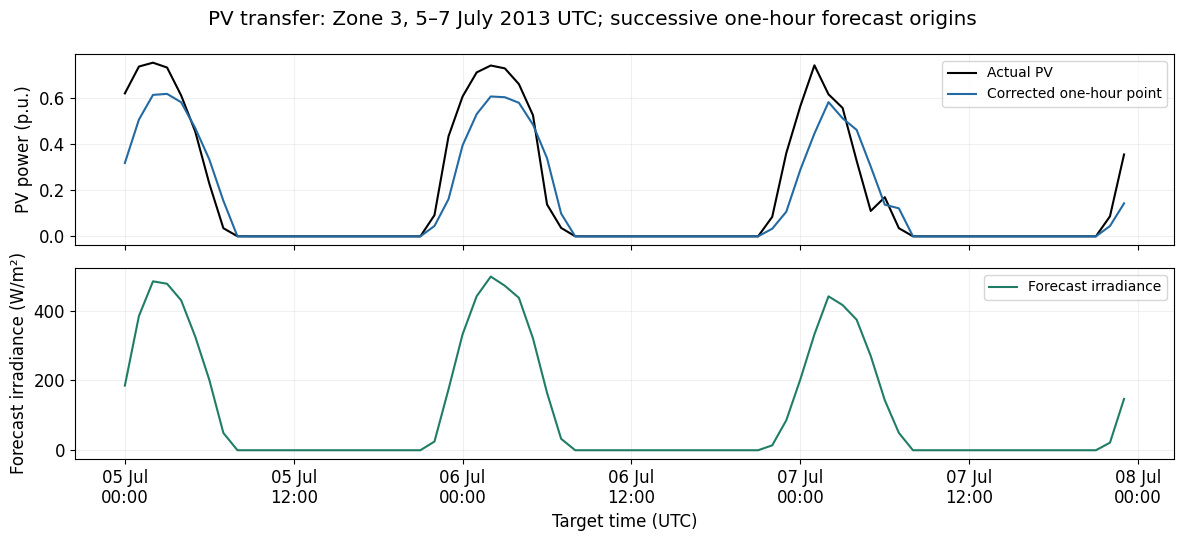

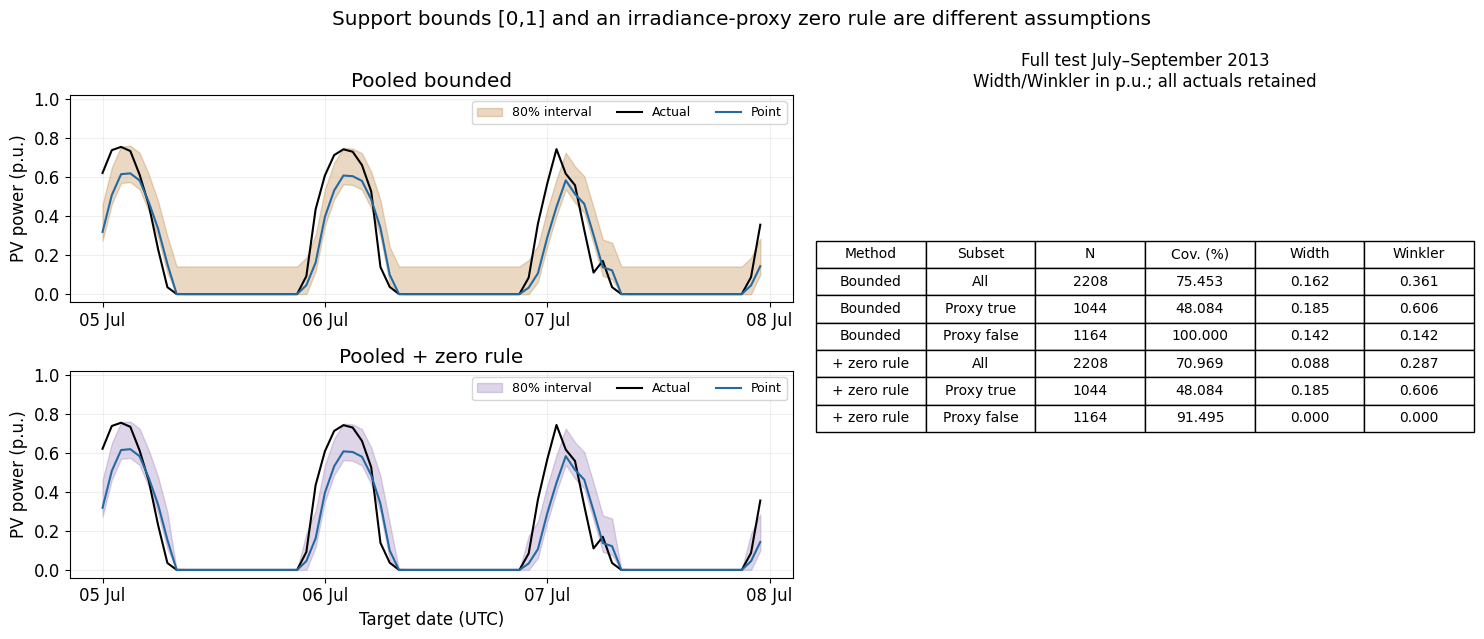

In [131]:
fig,axes = plt.subplots(2,1,figsize=(12,5.5),sharex=True)
axes[0].plot(pv_window.index,pv_window["actual"],color="black",label="Actual PV")
axes[0].plot(pv_window.index,pv_window["corrected_forecast"],color=COLOURS["point"],label="Corrected one-hour point")
axes[0].set(ylabel="PV power (p.u.)"); axes[0].legend(fontsize=10)
axes[1].plot(pv_window.index,pv_window[PV_WEATHER[0]],color=COLOURS["Target-hour"],label="Forecast irradiance")
axes[1].set(ylabel="Forecast irradiance (W/m²)",xlabel="Target time (UTC)")
axes[1].legend(fontsize=10)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M",tz=pv_window.index.tz))
fig.suptitle("PV transfer: Zone 3, 5–7 July 2013 UTC; successive one-hour forecast origins")
export_figure(fig,"U18","w4d2_U18_pv_transfer",30,"U8","2013-07-05 to 2013-07-07 UTC",
              "p.u.; W/m²","Separate aligned PV/forecast-irradiance panels",len(pv_window),source_hash=PV_HASH)

fig = plt.figure(figsize=(15,6.5))
grid = fig.add_gridspec(2,2,width_ratios=[1.1,1])
axes = [fig.add_subplot(grid[0,0]),fig.add_subplot(grid[1,0])]
table_ax = fig.add_subplot(grid[:,1]); table_ax.axis("off")
for ax,(name,bounds),colour in zip(axes,pv_methods.items(),[COLOURS["Pooled"],COLOURS["zero"]]):
    selected = bounds.loc[pv_window.index]
    ax.fill_between(pv_window.index,selected["lower"],selected["upper"],color=colour,alpha=.25,label="80% interval")
    ax.plot(pv_window.index,pv_window["actual"],color="black",label="Actual")
    ax.plot(pv_window.index,pv_window["corrected_forecast"],color=COLOURS["point"],label="Point")
    ax.set(title=name,ylabel="PV power (p.u.)",ylim=(-.04,1.02))
    ax.xaxis.set_major_locator(mdates.DayLocator(tz=pv_window.index.tz))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b",tz=pv_window.index.tz))
    ax.legend(fontsize=9,ncol=3)
axes[-1].set_xlabel("Target date (UTC)")
short_pv = pv_scores.copy()
short_pv["Method"] = short_pv["Method"].replace({"Pooled bounded":"Bounded","Pooled + zero rule":"+ zero rule"})
short_pv = short_pv.rename(columns={"Coverage (%)":"Cov. (%)","Width (p.u.)":"Width","Winkler (p.u.)":"Winkler"})
cells = [[f"{v:.3f}" if isinstance(v,float) else str(v) for v in row] for row in short_pv.replace({np.nan:"undefined"}).to_numpy()]
artist = table_ax.table(cellText=cells,colLabels=short_pv.columns,loc="center",cellLoc="center")
artist.auto_set_font_size(False); artist.set_fontsize(10); artist.scale(1,1.7)
table_ax.set_title("Full test July–September 2013\nWidth/Winkler in p.u.; all actuals retained",fontsize=12)
fig.suptitle("Support bounds [0,1] and an irradiance-proxy zero rule are different assumptions")
export_figure(fig,"U19","w4d2_U19_pv_bounds_and_proxy",31,"U8","Plots 5–7 July; full scores July–September 2013 UTC",
              "p.u.; %; counts","Bounded pooled versus added-zero intervals and full/subset scores",pv_proxy_counts,source_hash=PV_HASH)

### Task F: transfer the principles (6 minutes + 4 debrief)

Use the supplied results to discuss:

1. Which parts of error calibration and scoring transfer unchanged from building load to PV?
2. How does support clipping differ from forcing [0,0] using a forecast-irradiance proxy?
   Use the all-hours and subset scores to support your answer.
3. Why can these successive one-hour PV updates not be relabelled as a day-ahead joint scenario?

No code completion is required in this PV section. Do not tune a PV method on the test set.

In [132]:
print("Task F: error sign, calibration/test separation, quantile levels and score definitions transfer unchanged; units and valid support change.")
print(f"The full PV test retains {pv_proxy_counts['positive_actual_false_proxy']} positive actuals among {pv_proxy_counts['false_proxy_count']} false-proxy hours. [0,0] misses these; [0,1] support clipping does not declare them impossible.")
print("Hourly origins can use newly observed PV at later origins. A day-ahead trajectory must instead use only the one common origin's information and origin-consistent dependence.")

Task F: error sign, calibration/test separation, quantile levels and score definitions transfer unchanged; units and valid support change.
The full PV test retains 99 positive actuals among 1164 false-proxy hours. [0,0] misses these; [0,1] support clipping does not declare them impossible.
Hourly origins can use newly observed PV at later origins. A day-ahead trajectory must instead use only the one common origin's information and origin-consistent dependence.


## Recap

State one finding supported by the results and one limitation. Distinguish training,
calibration and testing; compare coverage and width together; and explain why hourly
prediction intervals do not determine uncertainty in daily energy.

The following extensions are self-study exercises, outside the 200-minute lecture.
Complete them after the core tutorial. Their model choices are specified in advance,
not selected using test performance.

## Extension 1 — Linear quantile regression

We estimate the conditional 10th and 90th quantiles directly:
$q_{\tau}(\mathbf{x}_t)=\beta_{0,\tau}+\mathbf{x}_t^\top\boldsymbol{\beta}_{\tau}$.
Each model minimises pinball loss with an L1 penalty. We specify
`alpha=0.1` before testing and use the same seven features and training-only scaler
as the Ridge model. Here `alpha` is the regularisation parameter, not the
miscoverage probability used in the Winkler score.

Train each model on January–June observations, not on calibration or test data.
Unlike the earlier intervals, these models predict quantiles directly rather than
adding calibration-error quantiles to a point forecast.
See the [QuantileRegressor documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.QuantileRegressor.html).

### E1a — Estimate the 10th quantile
Train the model and generate an indexed series of test quantile forecasts.

In [164]:
q10_model = QuantileRegressor(quantile=.10, solver="highs", alpha=0.001)
q10_model.fit(X_train_scaled, y_train)
q10_raw = pd.Series(q10_model.predict(X_test_scaled), index=test.index, name="q10")

### E1b — Estimate the 90th quantile

Repeat the calculation for $\tau=0.90$. Do not refit the scaler on test data.

In [165]:
q90_model = QuantileRegressor(quantile=.90, solver="highs", alpha=0.001)
q90_model.fit(X_train_scaled, y_train)
q90_raw = pd.Series(q90_model.predict(X_test_scaled), index=test.index, name="q90")

### Compare the three interval methods

Independent quantile models can cross. Retain the raw predictions, order the two
endpoints for each timestamp and project negative bounds to zero before scoring.
These corrections enforce ordering and nonnegativity; they do not guarantee calibration.

**Question:** how do coverage, mean width and Winkler compare with the pooled and
hour-conditioned intervals? Use the full test period, not only the plotted week.

Raw quantile crossings: 0


,Method,N,Coverage (%),Width (kWh),Winkler (kWh)
0,Pooled,672,75.595,90.934,132.784
1,Target-hour,672,74.256,89.153,130.720
2,Quantile regression,672,58.185,67.773,146.329


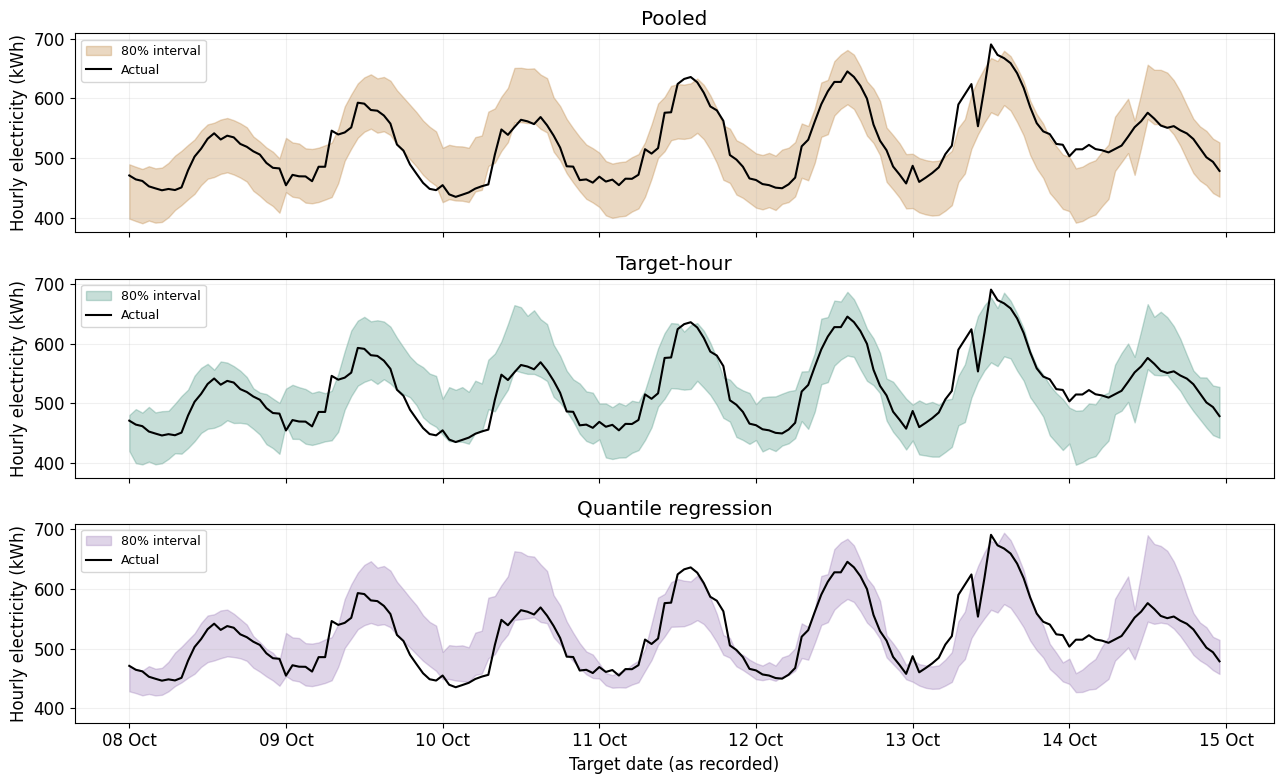

In [166]:
quantile_crossings = int((q10_raw > q90_raw).sum())
qr_raw = pd.DataFrame({"q10": q10_raw, "q90": q90_raw})
qr_bounds = pd.DataFrame({"lower": qr_raw.min(axis=1), "upper": qr_raw.max(axis=1)}).clip(lower=0)
comparison_methods = {**intervals, "Quantile regression": qr_bounds}
qr_rows = []
for name, bounds in comparison_methods.items():
    a, l, u = test["actual"], bounds["lower"], bounds["upper"]
    qr_rows.append({"Method": name, "N": len(a), "Coverage (%)": coverage(a, l, u),
                    "Width (kWh)": mean_width(a, l, u), "Winkler (kWh)": winkler(a, l, u)})
qr_scores = pd.DataFrame(qr_rows)
print("Raw quantile crossings:", quantile_crossings)
display(qr_scores.round(3))
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True, sharey=True)
for ax, (name, bounds) in zip(axes, comparison_methods.items()):
    selected = bounds.loc[window.index]
    ax.fill_between(window.index, selected["lower"], selected["upper"], alpha=.25,
                    color=COLOURS.get(name, "#8058a5"), label="80% interval")
    ax.plot(window.index, window["actual"], color="black", label="Actual")
    ax.set(title=name, ylabel="Hourly electricity (kWh)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.legend(fontsize=9)
axes[-1].set_xlabel("Target date (as recorded)")
export_figure(fig, "E01", "w4d2_E01_quantile_regression", "", "Extension 1",
              "Plot 8–14 October; full scores 1–28 October 2017", "kWh; %",
              "Direct quantile regression compared with error-based intervals", 672)

In [167]:
best_qr_comparison = qr_scores.loc[qr_scores["Winkler (kWh)"].idxmin()]
print(f"Extension 1: {best_qr_comparison['Method']} has the lowest test Winkler ({best_qr_comparison['Winkler (kWh)']:.3f} kWh).")
print("Compare this with coverage and width. Ordering and nonnegative projection enforce valid bounds, not nominal coverage.")

Extension 1: Target-hour has the lowest test Winkler (130.720 kWh).
Compare this with coverage and width. Ordering and nonnegative projection enforce valid bounds, not nominal coverage.


## Extension 2 — Gaussian error models and scenarios

The empirical scenarios used complete observed daily error vectors. We now compare
two parametric assumptions on the same 8 October forecast:

1. A single normal distribution $\mathcal{N}(\mu,\sigma^2)$ estimated from all
   calibration errors. Sample each scenario hour independently from this distribution.
2. A multivariate normal distribution $\mathcal{N}(\boldsymbol{\mu},\boldsymbol{\Sigma})$,
   estimated from the 92 daily calibration-error vectors. Its mean has 24 entries and
   its covariance matrix has shape $24\times24$.

Both use calibration errors only and retain their estimated means. The multivariate
model changes both hourly distributions and dependence relative to the pooled model.
This is not the controlled marginal-preserving experiment used in Task E.
A histogram alone does not establish Gaussian errors; normality remains an assumption.

### E2a — Independent draws from one fitted normal distribution

Estimate the mean and sample standard deviation of all calibration errors.
Generate 500 vectors of length 24 using `rng_normal.normal(..., size=(500, 24))`.
Add them to the target point profile and project negative scenarios to zero.
Keep the raw values for comparison.

In [168]:
normal_mean = calibration["error"].mean()
normal_std = calibration["error"].std(ddof=1)
rng_normal = np.random.default_rng(SEED)
normal_errors = rng_normal.normal(normal_mean, normal_std, size=(500, 24))
normal_scenarios_raw = target_profile[None, :] + normal_errors
normal_scenarios = np.maximum(0, normal_scenarios_raw)

### E2b — Multivariate normal draws

Estimate the 24 hourly means with `residual_matrix.mean(axis=0)` and covariance with
`residual_matrix.cov()`. The variable `residual_matrix` stores the daily calibration
errors constructed in U7. Draw 500 vectors using `rng_joint.multivariate_normal`.

Each simulated vector represents a complete day issued from one common origin.
A covariance estimate from only 92 days remains uncertain, and transferring summer
error patterns to October requires the same stability assumption as before.

In [169]:
joint_mean = residual_matrix.mean(axis=0).to_numpy()
joint_covariance = residual_matrix.cov().to_numpy()
rng_joint = np.random.default_rng(SEED)
joint_errors = rng_joint.multivariate_normal(joint_mean, joint_covariance, size=500)
joint_scenarios_raw = target_profile[None, :] + joint_errors
joint_scenarios = np.maximum(0, joint_scenarios_raw)

### Compare trajectories, dependence and daily energy

**Predict:** which assumption should produce more persistent errors across hours?
The supplied plot uses the same target day, sample count and axes for both models.

For comparison with the empirical pooled interval, we also construct analytical 80%
bounds from the fitted normal distribution, $\hat y_t+\mu\pm z_{0.90}\sigma$.
After nonnegative projection, evaluate them on the same full test period.

,Method,Coverage (%),Width (kWh),Winkler (kWh)
0,Empirical pooled,75.595,90.934,132.784
1,Normal pooled,79.315,97.705,131.870


,Independent pooled,Multivariate
mean,11445.153,11459.372
std,186.804,621.913


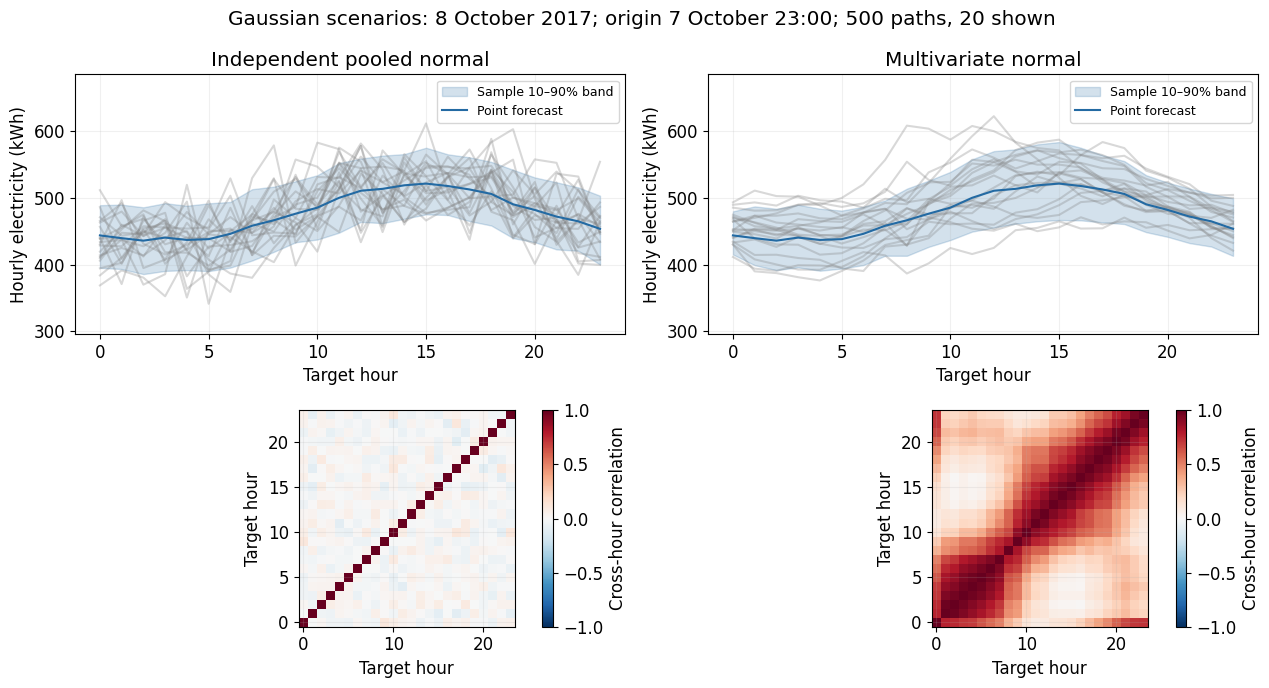

Negative scenario projections: 0 0


In [170]:
from statistics import NormalDist
z90 = NormalDist().inv_cdf(.90)
normal_bounds = pd.DataFrame(index=test.index)
normal_bounds["lower"] = test["corrected_forecast"] + normal_mean - z90*normal_std
normal_bounds["upper"] = test["corrected_forecast"] + normal_mean + z90*normal_std
normal_bounds = normal_bounds.clip(lower=0)
gaussian_interval_scores = pd.DataFrame([
    {"Method": name, "Coverage (%)": coverage(test["actual"], bounds["lower"], bounds["upper"]),
     "Width (kWh)": mean_width(test["actual"], bounds["lower"], bounds["upper"]),
     "Winkler (kWh)": winkler(test["actual"], bounds["lower"], bounds["upper"])}
    for name, bounds in [("Empirical pooled", pooled_bounded), ("Normal pooled", normal_bounds)]])
display(gaussian_interval_scores.round(3))
gaussian_energy = pd.DataFrame({"Independent pooled": normal_scenarios.sum(axis=1),
                               "Multivariate": joint_scenarios.sum(axis=1)})
display(gaussian_energy.agg(["mean", "std"]).round(3))
fig, axes = plt.subplots(2, 2, figsize=(13, 7), gridspec_kw={"height_ratios": [1.2, 1]})
for column, (name, values) in enumerate([("Independent pooled normal", normal_scenarios),
                                        ("Multivariate normal", joint_scenarios)]):
    band = np.quantile(values, [.10, .90], axis=0)
    axes[0, column].fill_between(np.arange(24), band[0], band[1], color=COLOURS["point"],
                                 alpha=.2, label="Sample 10–90% band")
    axes[0, column].plot(np.arange(24), values[:20].T, color=COLOURS["scenario"], alpha=.3)
    axes[0, column].plot(np.arange(24), target_profile, color=COLOURS["point"], label="Point forecast")
    axes[0, column].set(title=name, xlabel="Target hour", ylabel="Hourly electricity (kWh)")
    axes[0, column].legend(fontsize=9)
    corr = np.corrcoef(values, rowvar=False)
    mesh = axes[1, column].pcolormesh(np.arange(25)-.5, np.arange(25)-.5, corr,
                                     cmap="RdBu_r", vmin=-1, vmax=1)
    axes[1, column].set(xlabel="Target hour", ylabel="Target hour", aspect="equal")
    colourbar = fig.colorbar(mesh, ax=axes[1, column], label="Cross-hour correlation")
    colourbar.solids.set_rasterized(False)
limits = (min(normal_scenarios.min(), joint_scenarios.min())-10,
          max(normal_scenarios.max(), joint_scenarios.max())+10)
for ax in axes[0]: ax.set_ylim(limits)
fig.suptitle("Gaussian scenarios: 8 October 2017; origin 7 October 23:00; 500 paths, 20 shown")
export_figure(fig, "E02", "w4d2_E02_gaussian_scenarios", "", "Extension 2",
              "8 October 2017; July–September calibration", "kWh; correlation",
              "Pooled independent versus multivariate Gaussian error assumptions", 500,
              status="illustrative empirical")
print("Negative scenario projections:", int((normal_scenarios_raw < 0).sum()),
      int((joint_scenarios_raw < 0).sum()))

**Question:** explain how the covariance terms affect daily-energy uncertainty:
$\operatorname{Var}(\sum_hY_h)=\sum_h\operatorname{Var}(Y_h)+2\sum_{h<j}\operatorname{Cov}(Y_h,Y_j)$.
Why does this comparison change more than dependence alone? State one limitation of
the Gaussian assumption or the estimated covariance matrix.

In [171]:
print("Extension 2: positive cross-hour covariance increases variance of the daily sum.")
print("The pooled normal also assumes the same mean and variance at every hour; the multivariate model relaxes both assumptions.")
print("Finite samples, seasonal changes and non-Gaussian tails limit these fitted distributions; scenario plots do not establish calibration.")

Extension 2: positive cross-hour covariance increases variance of the daily sum.
The pooled normal also assumes the same mean and variance at every hour; the multivariate model relaxes both assumptions.
Finite samples, seasonal changes and non-Gaussian tails limit these fitted distributions; scenario plots do not establish calibration.


## Extension 3 — PV intervals by target hour

Applying Task B to PV allows a direct comparison with the pooled error intervals.
Group by **UTC target hour**, estimate the 10th and 90th calibration-error quantiles
and add them to the corrected PV point forecast. Clip both endpoints to $[0,1]$.
Do not apply the additional irradiance zero rule in this comparison, so the only
method change is hour conditioning.

Each hour has 91 calibration observations. Compare all-hours and forecast-solar-available
scores; night-time zeros can conceal poor performance during generation hours.
These hourly PV updates do not form a day-ahead joint forecast.

In [172]:
pv_hour_offsets = pv_cal.groupby(pv_cal.index.hour)["error"].quantile([.10, .90]).unstack()
pv_hourly_raw = pd.DataFrame(index=pv_test.index)
pv_hours = pd.Series(pv_test.index.hour, index=pv_test.index)
pv_hourly_raw["lower"] = pv_test["corrected_forecast"] + pv_hours.map(pv_hour_offsets[.10])
pv_hourly_raw["upper"] = pv_test["corrected_forecast"] + pv_hours.map(pv_hour_offsets[.90])
pv_hourly_bounds = pv_hourly_raw.clip(0, 1)

,Method,Subset,N,Coverage (%),Width (p.u.),Winkler (p.u.)
0,Pooled bounded,All,2208,75.453,0.162,0.361
1,Pooled bounded,Proxy true,1044,48.084,0.185,0.606
2,Pooled bounded,Proxy false,1164,100.000,0.142,0.142
3,Target-hour bounded,All,2208,79.937,0.096,0.200
4,Target-hour bounded,Proxy true,1044,62.452,0.204,0.422
5,Target-hour bounded,Proxy false,1164,95.619,0.000,0.000


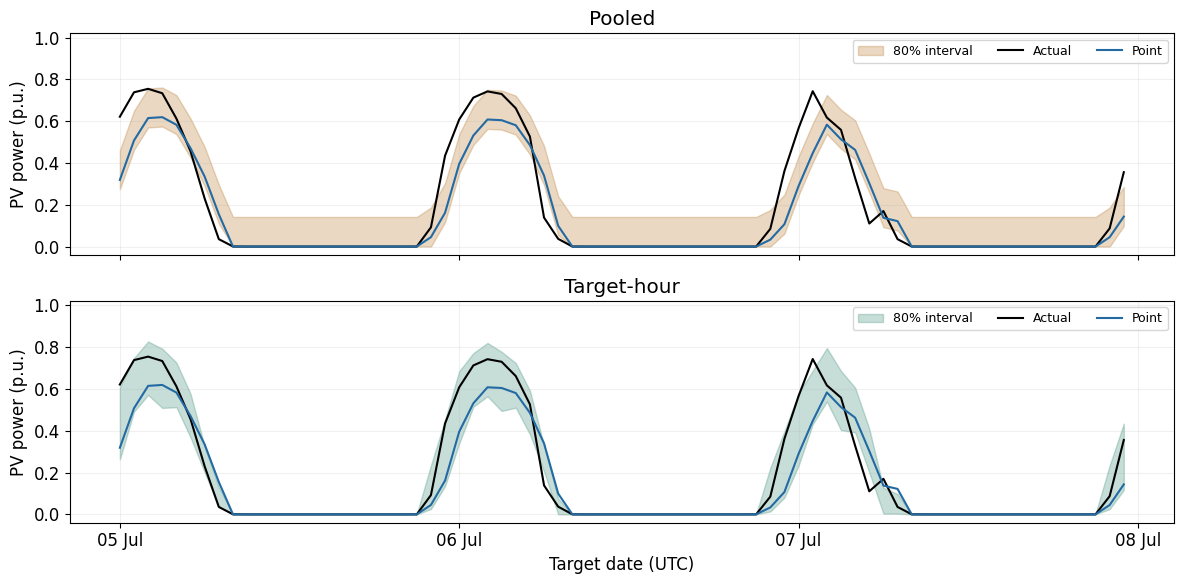

In [173]:
pv_hourly_rows = []
for name, bounds in [("Pooled bounded", pv_bounded), ("Target-hour bounded", pv_hourly_bounds)]:
    for subset, mask in pv_subsets.items():
        a, l, u = pv_test.loc[mask, "actual"], bounds.loc[mask, "lower"], bounds.loc[mask, "upper"]
        pv_hourly_rows.append({"Method": name, "Subset": subset, "N": len(a),
                              "Coverage (%)": coverage(a, l, u), "Width (p.u.)": mean_width(a, l, u),
                              "Winkler (p.u.)": winkler(a, l, u)})
pv_hourly_scores = pd.DataFrame(pv_hourly_rows)
display(pv_hourly_scores.round(3))
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, (name, bounds) in zip(axes, [("Pooled", pv_bounded), ("Target-hour", pv_hourly_bounds)]):
    selected = bounds.loc[pv_window.index]
    ax.fill_between(pv_window.index, selected["lower"], selected["upper"],
                    color=COLOURS[name], alpha=.25, label="80% interval")
    ax.plot(pv_window.index, pv_window["actual"], color="black", label="Actual")
    ax.plot(pv_window.index, pv_window["corrected_forecast"], color=COLOURS["point"], label="Point")
    ax.set(title=name, ylabel="PV power (p.u.)", ylim=(-.04, 1.02))
    ax.xaxis.set_major_locator(mdates.DayLocator(tz=pv_window.index.tz))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=pv_window.index.tz))
    ax.legend(fontsize=9, ncol=3)
axes[-1].set_xlabel("Target date (UTC)")
export_figure(fig, "E03", "w4d2_E03_pv_hourly_intervals", "", "Extension 3",
              "Plot 5–7 July; full scores July–September 2013 UTC", "p.u.; %",
              "Pooled versus UTC-hour-conditioned PV error intervals; same support clipping",
              "2208 test; 91 calibration/hour", source_hash=PV_HASH)

In [174]:
print("Extension 3: compare forecast-solar-available coverage alongside the all-hours score.")
print("Hour conditioning changes the estimated error spread across the day, but does not guarantee nominal coverage or identify astronomical night.")

Extension 3: compare forecast-solar-available coverage alongside the all-hours score.
Hour conditioning changes the estimated error spread across the day, but does not guarantee nominal coverage or identify astronomical night.


### References and data credits

- Miller et al. (2020), *The Building Data Genome Project 2, energy meter data from the ASHRAE
  Great Energy Predictor III competition*, Scientific Data, 7, 368.
  [Paper](https://doi.org/10.1038/s41597-020-00712-x), [dataset](https://github.com/buds-lab/building-data-genome-project-2).
  CC BY-SA 4.0 attribution is retained. Margarito is a pseudonym, not the public building name.
  [Robin source README](data/week4_day1/robin/README.md) documents unchanged values and upstream cleaning.
- Hong et al. (2016), *Probabilistic energy forecasting: Global Energy Forecasting Competition
  2014 and beyond*, International Journal of Forecasting, 32(3), 896–913.
  [Paper](https://doi.org/10.1016/j.ijforecast.2016.02.001), [PV provenance](data/tutorial_4_2/README.md).
- Gneiting and Katzfuss (2014), *Probabilistic Forecasting*, Annual Review of Statistics and Its
  Application, 1, 125–151. [Paper](https://doi.org/10.1146/annurev-statistics-062713-085831).
- Gneiting and Raftery (2007), *Strictly Proper Scoring Rules, Prediction, and Estimation*.
  [Paper](https://doi.org/10.1198/016214506000001437).
- Koenker and Bassett (1978), *Regression Quantiles*. [Paper](https://doi.org/10.2307/1913643).
- Hyndman and Athanasopoulos (2021), *Forecasting: Principles and Practice*,
  [Section 5.9](https://otexts.com/fpp3/toolbox.html#winkler-score). Its quantile score is doubled
  relative to our pinball convention.
- Drgoňa et al. (2020), *All you need to know about model predictive control for buildings*.
  [Paper](https://doi.org/10.1016/j.arcontrol.2020.09.001). Control is motivation, not an implemented task here.

In [175]:
# Supplied exports for lecture figures and reproducibility; not needed for model fitting.
if EXPORT_ARTEFACTS:
    outputs = {"building_calibration_predictions.csv": calibration, "building_test_predictions.csv": test,
               "building_daily_errors.csv": residual_matrix, "building_interval_scores.csv": score_table,
               "building_hourly_scores.csv": hourly_scores, "building_level_scores.csv": level_scores,
               "building_energy_summary.csv": energy_summary, "building_quantile_scores.csv": qr_scores,
               "building_gaussian_interval_scores.csv": gaussian_interval_scores,
               "pv_calibration_predictions.csv": pv_cal, "pv_test_predictions.csv": pv_test,
               "pv_interval_scores.csv": pv_scores, "pv_hourly_interval_scores.csv": pv_hourly_scores}
    for filename, frame in outputs.items():
        frame.to_csv(DATA_DIR / filename)
    interval_records.to_csv(DATA_DIR / "building_interval_records.csv", index=False)
    manifest = pd.DataFrame(figure_records).drop_duplicates("filename", keep="last")
    manifest.sort_values(["figure_id", "variant", "filename"]).to_csv(
        ROOT / "teaching/week4_day2_figure_manifest.csv", index=False)
    versions = {name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scikit-learn", "matplotlib"]}
    versions["python"] = platform.python_version()
    run_metadata = {"source_hashes": {"building": BUILDING_HASH, "pv": PV_HASH},
                    "versions": versions, "seed": SEED, "building_splits": BUILDING_SPLITS,
                    "building_features": FEATURE_COLUMNS, "ridge_alpha": 10.,
                    "pv_splits": PV_SPLITS, "pv_features": PV_FEATURES,
                    "counts": {"training": len(X_train), "calibration": len(calibration), "test": len(test),
                               "daily_error_matrix": list(residual_matrix.shape)},
                    "point_clip_counts": point_clips, "endpoint_clip_counts": endpoint_clips,
                    "pv_target_changes": pv_altered.reset_index().astype(str).to_dict("records"),
                    "pv_proxy_counts": pv_proxy_counts,
                    "extension_models": {"quantile_levels": [.10, .90], "quantile_regularisation": .1,
                                         "gaussian_samples": 500},
                    "timing": {"teaching_minutes": 200, "break_minutes": [15, 20],
                               "pv_minutes": 25, "extensions": "self-study, outside lecture timing"}}
    (DATA_DIR / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2), encoding="utf-8")
print("Complete. Instructor: python teaching/validate_week4_day2.py")

Complete. Instructor: python teaching/validate_week4_day2.py
